MSc Project Notebook:- AI-POWERED PREDICTIVE ANALYTICS PLATFORM FOR WINERIES

Name:- Roshan Chiragkumar Pattharwala

Student ID:- A00062620


#Importing libraries and environment setup


In [1]:
import sys
import subprocess
import importlib
import os
import warnings

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "joblib": "joblib",
    "scipy": "scipy",
    "shap": "shap"
}
for package, pip_name in required_packages.items():
    try:
        importlib.import_module(package)
    except ImportError:
        print(f"Installing {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import gaussian_kde

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

# GLOBAL VISUALISATION CONFIGURATION
# Apply a professional, publication-quality aesthetic to all matplotlib figures.

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f9f9f9',
    'axes.grid': True,
    'grid.alpha': 0.4,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'font.family': 'DejaVu Sans'
})

# Set seaborn style for polished, academic plots
sns.set_style('whitegrid')
sns.set_palette('Set2')

# Global random seed for reproducibility
RANDOM_STATE = 42

print("=" * 60)
print("All libraries imported successfully.")
print("=" * 60)

print(f"Pandas      : {pd.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"Matplotlib  : {plt.matplotlib.__version__}")
print(f"Seaborn     : {sns.__version__}")
print(f"Scikit-Learn: {__import__('sklearn').__version__}")
print(f"XGBoost     : {__import__('xgboost').__version__}")
print(f"LightGBM    : {__import__('lightgbm').__version__}")
print(f"Joblib      : {joblib.__version__}")

print("\nEnvironment setup completed successfully.")


All libraries imported successfully.
Pandas      : 2.2.3
NumPy       : 2.4.6
Matplotlib  : 3.10.0
Seaborn     : 0.13.2
Scikit-Learn: 1.6.1
XGBoost     : 3.4.1
LightGBM    : 4.6.0
Joblib      : 1.6.0

Environment setup completed successfully.


# Step 1 — Data Ingestion & Enterprise Merging

In [ ]:
# --- Load Red Wine Dataset ---
df_red = pd.read_csv('winequality-red.csv', sep=';')

# --- Inject Binary Wine-Type Origin Column ---
# is_red = 1 flags every row as originating from the red wine dataset.
# This preserves wine-type traceability after concatenation.
df_red['is_red'] = 1

# --- Load White Wine Dataset ---
df_white = pd.read_csv('winequality-white.csv', sep=';')

# is_red = 0 flags every row as originating from the white wine dataset
df_white['is_red'] = 0

# --- Enterprise Concatenation ---
# Vertically stack both DataFrames. ignore_index=True resets the index
# to a clean 0-based integer sequence across the merged dataset.
df = pd.concat([df_red, df_white], axis=0, ignore_index=True)

print("=" * 60)
print("   ENTERPRISE DATASET — INGESTION REPORT")
print("=" * 60)
print(f"  Red wine rows loaded    : {len(df_red):,}")
print(f"  White wine rows loaded  : {len(df_white):,}")
print(f"  Total rows after merge  : {df.shape[0]:,}")
print(f"  Total columns           : {df.shape[1]}")
print("=" * 60)
print()

print("--- First Five Rows ---")
display(df.head())

print("--- Last Five Rows ---")
display(df.tail())

print(f"  Shape  : {df.shape}")
print(f"  Rows   : {df.shape[0]:,}")
print(f"  Columns: {df.shape[1]}")
print()
print("Enterprise dataset successfully created and verified.")

   ENTERPRISE DATASET — INGESTION REPORT
  Red wine rows loaded    : 1,599
  White wine rows loaded  : 4,898
  Total rows after merge  : 6,497
  Total columns           : 13

--- First Five Rows ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


--- Last Five Rows ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,0
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,0
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,0
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,0
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,0


  Shape  : (6497, 13)
  Rows   : 6,497
  Columns: 13

Enterprise dataset successfully created and verified.


# Step 2 — Structural & Statistical Data Understanding

In [ ]:
print("=" * 60)
print("   COMPLETE DATA AUDIT REPORT")
print("=" * 60)

# --- Shape ---
print(f"\n[1] SHAPE: {df.shape[0]:,} rows × {df.shape[1]} columns")

# --- Data Types ---
print("\n[2] DATA TYPES:")
print(df.dtypes.to_string())

# --- Missing Values ---
missing = df.isnull().sum()
print(f"\n[3] MISSING VALUES (total): {missing.sum()}")
print(missing[missing > 0] if missing.sum() > 0 else "   → No missing values detected.")

# --- Duplicate Rows ---
dupes = df.duplicated().sum()
print(f"\n[4] DUPLICATE ROWS: {dupes}")
if dupes > 0:
    print("   → Exact duplicate records detected.")
    print("   → All original records are retained.")
    print("   → Grouped splitting is applied during modelling to prevent data leakage.")
else:
    print("   → No exact duplicate rows detected.")

# --- Unique Values per Column ---
print("\n[5] UNIQUE VALUES PER COLUMN:")
print(df.nunique().to_string())

# --- Memory Usage ---
mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\n[6] MEMORY USAGE: {mem_mb:.3f} MB")

# --- Column Names ---
print(f"\n[7] COLUMN NAMES ({df.shape[1]} columns):")
for i, col in enumerate(df.columns, 1):
    print(f"   {i:2d}. {col}")

   COMPLETE DATA AUDIT REPORT

[1] SHAPE: 6,497 rows × 13 columns

[2] DATA TYPES:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
is_red                    int64

[3] MISSING VALUES (total): 0
   → No missing values detected.

[4] DUPLICATE ROWS: 1177
   → Exact duplicate records detected.
   → All original records are retained.
   → Grouped splitting is applied during modelling to prevent data leakage.

[5] UNIQUE VALUES PER COLUMN:
fixed acidity           106
volatile acidity        187
citric acid              89
residual sugar          316
chlorides               214
free sulfur dioxide     135
total sulfur dioxide    276
density                 998
p

In [ ]:
# --- Statistical Summary ---
print("\n[8] STATISTICAL SUMMARY:")
display(df.describe().T.round(4))


[8] STATISTICAL SUMMARY:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.2153,1.2964,3.8000,6.4000,7.0000,7.700,15.900
volatile acidity,6497.0,0.3397,0.1646,0.0800,0.2300,0.2900,0.400,1.580
citric acid,6497.0,0.3186,0.1453,0.0000,0.2500,0.3100,0.390,1.660
residual sugar,6497.0,5.4432,4.7578,0.6000,1.8000,3.0000,8.100,65.800
chlorides,6497.0,0.0560,0.0350,0.0090,0.0380,0.0470,0.065,0.611
free sulfur dioxide,6497.0,30.5253,17.7494,1.0000,17.0000,29.0000,41.000,289.000
total sulfur dioxide,6497.0,115.7446,56.5219,6.0000,77.0000,118.0000,156.000,440.000
density,6497.0,0.9947,0.0030,0.9871,0.9923,0.9949,0.997,1.039
pH,6497.0,3.2185,0.1608,2.7200,3.1100,3.2100,3.320,4.010
sulphates,6497.0,0.5313,0.1488,0.2200,0.4300,0.5100,0.600,2.000


In [ ]:
# DATA QUALITY SUMMARY TABLE
# A formal structured table covering column name, data type,
# missing values, unique values, and data quality remarks.

def build_data_quality_table(dataframe):
    """
    Constructs a formal Data Quality Summary table for the DataFrame.
    Returns a styled pandas DataFrame for display.
    """
    # Prepare remark logic for each column
    remarks_map = {
        'fixed acidity'       : 'Continuous physicochemical feature — no issues',
        'volatile acidity'    : 'Continuous; high values indicate wine defects',
        'citric acid'         : 'Continuous; 0 is a valid chemical value',
        'residual sugar'      : 'Right-skewed; extreme outliers present',
        'chlorides'           : 'Right-skewed; extreme outliers present',
        'free sulfur dioxide' : 'Continuous; range varies significantly',
        'total sulfur dioxide': 'Right-skewed; extreme outliers expected',
        'density'             : 'Continuous; narrow range — near-constant',
        'pH'                  : 'Continuous; valid acidic range (2.7–4.0)',
        'sulphates'           : 'Continuous; linked to antimicrobial properties',
        'alcohol'             : 'Continuous; % by volume — key quality predictor',
        'quality'             : 'INTEGER TARGET — multiclass (3–9); imbalanced',
        'is_red'              : 'Binary engineered feature: 1=red, 0=white'
    }

    rows = []
    for col in dataframe.columns:
        rows.append({
            'Column Name'   : col,
            'Data Type'     : str(dataframe[col].dtype),
            'Missing Values': dataframe[col].isnull().sum(),
            'Unique Values' : dataframe[col].nunique(),
            'Remarks'       : remarks_map.get(col, 'No remark')
        })

    return pd.DataFrame(rows)


dq_table = build_data_quality_table(df)

print("DATA QUALITY SUMMARY TABLE")
print("=" * 100)
display(dq_table)

DATA QUALITY SUMMARY TABLE


,Column Name,Data Type,Missing Values,Unique Values,Remarks
0,fixed acidity,float64,0,106,Continuous physicochemical feature — no issues
1,volatile acidity,float64,0,187,Continuous; high values indicate wine defects
2,citric acid,float64,0,89,Continuous; 0 is a valid chemical value
3,residual sugar,float64,0,316,Right-skewed; extreme outliers present
4,chlorides,float64,0,214,Right-skewed; extreme outliers present
5,free sulfur dioxide,float64,0,135,Continuous; range varies significantly
6,total sulfur dioxide,float64,0,276,Right-skewed; extreme outliers expected
7,density,float64,0,998,Continuous; narrow range — near-constant
8,pH,float64,0,108,Continuous; valid acidic range (2.7–4.0)
9,sulphates,float64,0,111,Continuous; linked to antimicrobial properties


# Step 3 — Target Class Imbalance Profiling

In [ ]:
# Analyse the distribution of the quality target variable to understand
# the class balance issue before model training.

# --- Value Counts and Percentage Distribution ---
quality_counts = df['quality'].value_counts().sort_index()
quality_pct    = (quality_counts / len(df) * 100).round(2)

print("TARGET VARIABLE: quality")
print("=" * 45)
print(f"{'Quality Score':<18} {'Count':>8} {'Percentage':>12}")
print("-" * 45)
for score, count in quality_counts.items():
    pct = quality_pct[score]
    bar = '' * int(pct / 2)
    print(f"  Quality {score:<8}    {count:>8,}   {pct:>8.2f}%  {bar}")
print("-" * 45)
print(f"  {'TOTAL':<15}    {len(df):>8,}   {'100.00%':>9}")
print("=" * 45)

# Identify dominant and rare classes
dominant = quality_counts[quality_counts / len(df) > 0.15].index.tolist()
rare     = quality_counts[quality_counts / len(df) < 0.05].index.tolist()
print(f"\n  Dominant classes (>15%): {dominant}")
print(f"  Rare classes     (<5%): {rare}")

TARGET VARIABLE: quality
Quality Score         Count   Percentage
---------------------------------------------
  Quality 3                 30       0.46%  
  Quality 4                216       3.32%  
  Quality 5              2,138      32.91%  
  Quality 6              2,836      43.65%  
  Quality 7              1,079      16.61%  
  Quality 8                193       2.97%  
  Quality 9                  5       0.08%  
---------------------------------------------
  TOTAL                 6,497     100.00%

  Dominant classes (>15%): [5, 6, 7]
  Rare classes     (<5%): [3, 4, 8, 9]


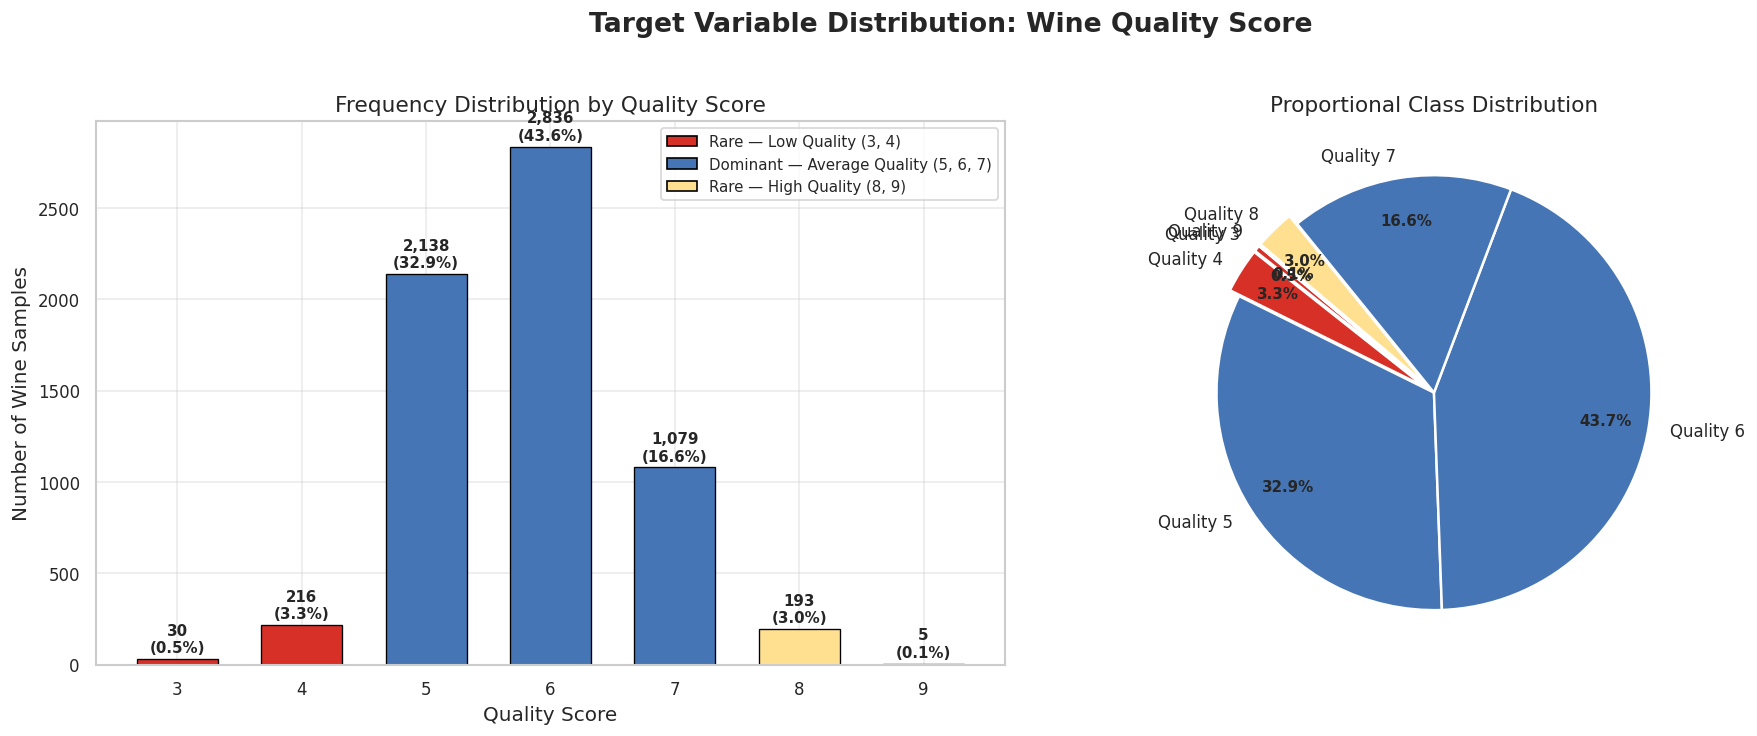


Class distribution charts generated and saved.


In [ ]:
# VISUALISATION — BAR CHART AND PIE CHART FOR CLASS DISTRIBUTION

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Target Variable Distribution: Wine Quality Score', fontsize=16, fontweight='bold', y=1.02)

# Colour palette — highlight dominant vs rare classes
palette = ['#d73027' if q in [3, 4] else '#fee090' if q in [8, 9] else '#4575b4'
           for q in quality_counts.index]

# --- Bar Chart ---
bars = axes[0].bar(quality_counts.index, quality_counts.values, color=palette,
                   edgecolor='black', linewidth=0.8, width=0.65)
axes[0].set_xlabel('Quality Score', fontsize=12)
axes[0].set_ylabel('Number of Wine Samples', fontsize=12)
axes[0].set_title('Frequency Distribution by Quality Score', fontsize=13)
axes[0].set_xticks(quality_counts.index)

# Annotate bars with count and percentage
for bar, (score, count) in zip(bars, quality_counts.items()):
    pct = quality_pct[score]
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 20,
                 f'{count:,}\n({pct:.1f}%)',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Legend for colour coding
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#d73027', edgecolor='black', label='Rare — Low Quality (3, 4)'),
    Patch(facecolor='#4575b4', edgecolor='black', label='Dominant — Average Quality (5, 6, 7)'),
    Patch(facecolor='#fee090', edgecolor='black', label='Rare — High Quality (8, 9)')
]
axes[0].legend(handles=legend_elements, loc='upper right', fontsize=9)

# --- Pie Chart ---
explode = [0.05 if q in [3, 4, 8, 9] else 0 for q in quality_counts.index]
wedges, texts, autotexts = axes[1].pie(
    quality_counts.values,
    labels=[f'Quality {q}' for q in quality_counts.index],
    autopct='%1.1f%%',
    startangle=140,
    colors=palette,
    explode=explode,
    pctdistance=0.80,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')
axes[1].set_title('Proportional Class Distribution', fontsize=13)

plt.tight_layout()
plt.savefig('class_distribution.png', bbox_inches='tight', dpi=150)
plt.show()
print("\nClass distribution charts generated and saved.")

# Step 4 — Exploratory Data Analysis (EDA)

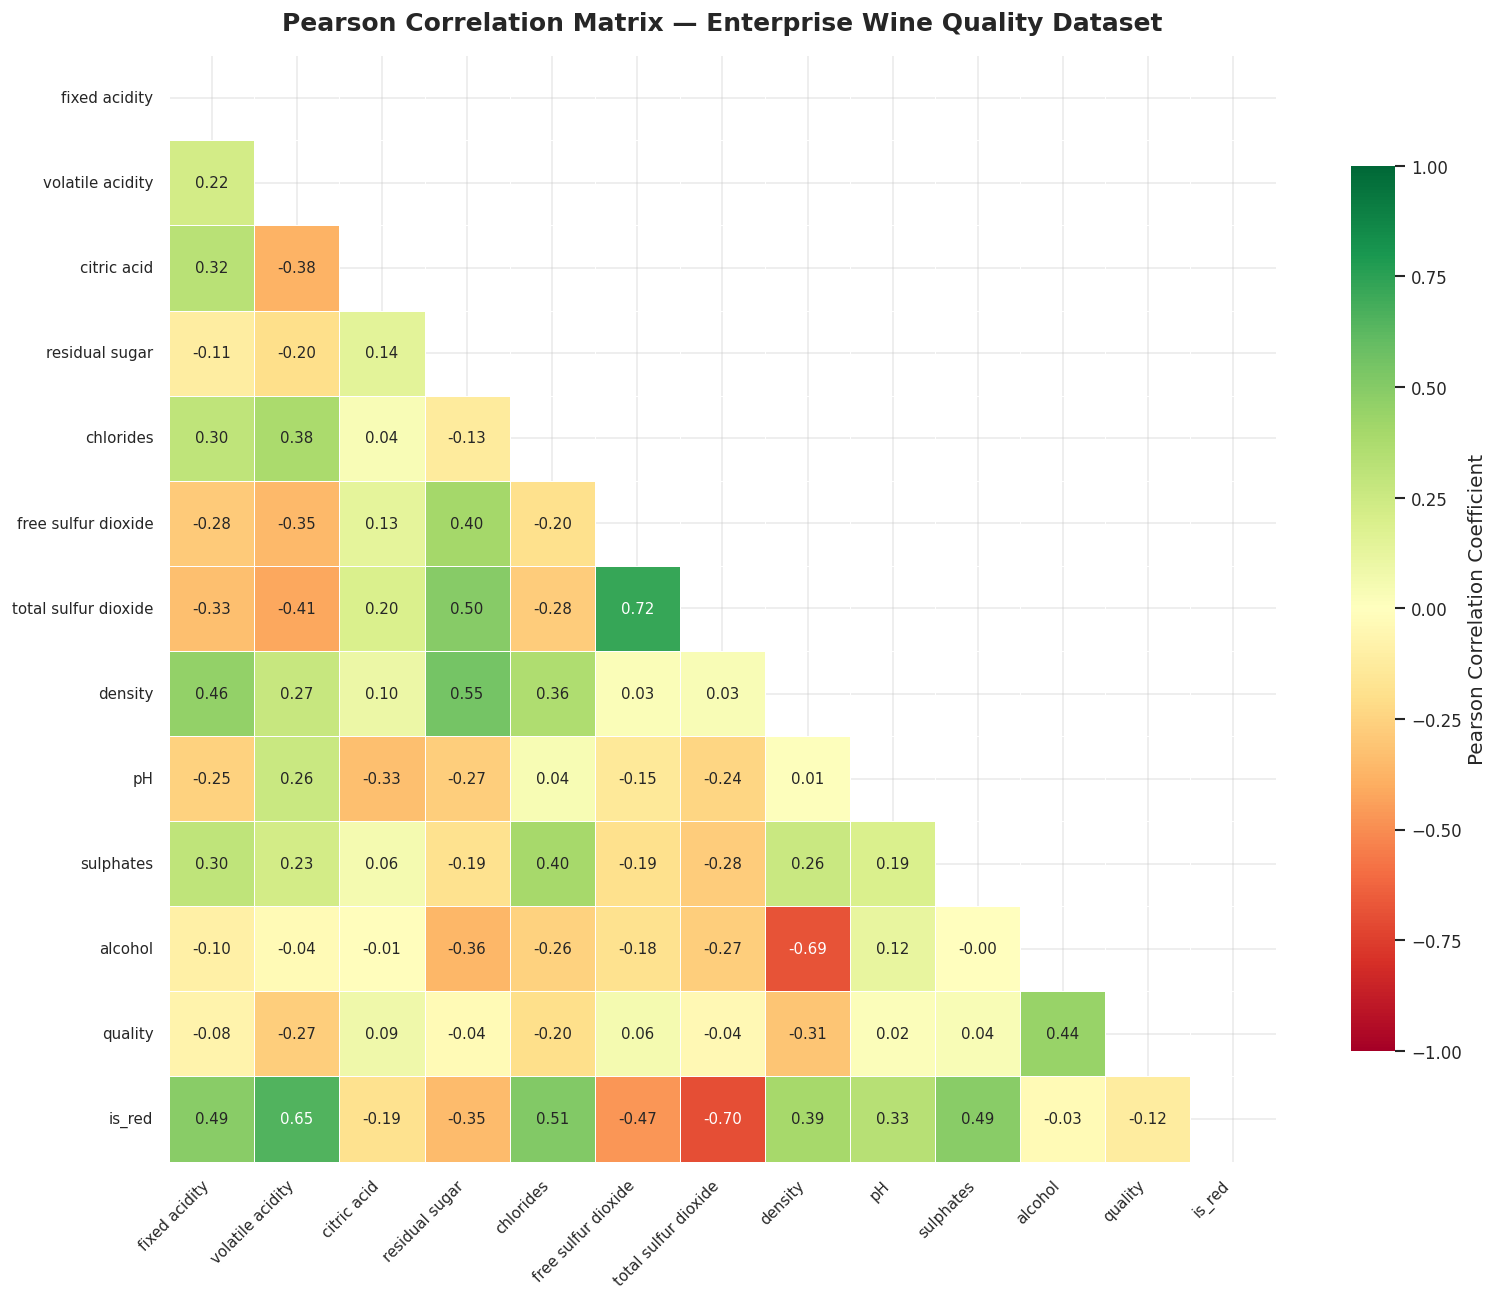

TOP CORRELATED FEATURE PAIRS (|r| > 0.50, excluding self-correlations):
-----------------------------------------------------------------


,Feature A,Feature B,Correlation
0,total sulfur dioxide,free sulfur dioxide,0.720934
1,is_red,total sulfur dioxide,-0.700357
2,alcohol,density,-0.686745
3,is_red,volatile acidity,0.653036
4,density,residual sugar,0.552517
5,is_red,chlorides,0.512678


In [ ]:
# STEP 4.1 — CORRELATION HEATMAP
# Compute a Pearson correlation matrix across all numeric features.
# Identify multicollinear feature pairs and examine feature-target correlations.

fig, ax = plt.subplots(figsize=(14, 11))

# Compute the Pearson correlation matrix for all numeric columns
corr_matrix = df.corr(numeric_only=True)

# Create a triangular mask to avoid duplicate information
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Draw the heatmap with annotation and diverging colour scale
heatmap = sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',        # Red = strong negative, Green = strong positive
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation Coefficient'},
    annot_kws={'size': 9},
    ax=ax
)

ax.set_title('Pearson Correlation Matrix — Enterprise Wine Quality Dataset',
             fontsize=15, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig('correlation_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()

# --- Print Top Correlated Feature Pairs ---
print("TOP CORRELATED FEATURE PAIRS (|r| > 0.50, excluding self-correlations):")
print("-" * 65)
upper_tri = corr_matrix.where(~mask)
high_corr = (
    upper_tri.stack()
    .reset_index()
    .rename(columns={'level_0': 'Feature A', 'level_1': 'Feature B', 0: 'Correlation'})
)
high_corr = high_corr[high_corr['Correlation'].abs() > 0.50].sort_values('Correlation', key=abs, ascending=False)
display(high_corr.reset_index(drop=True))

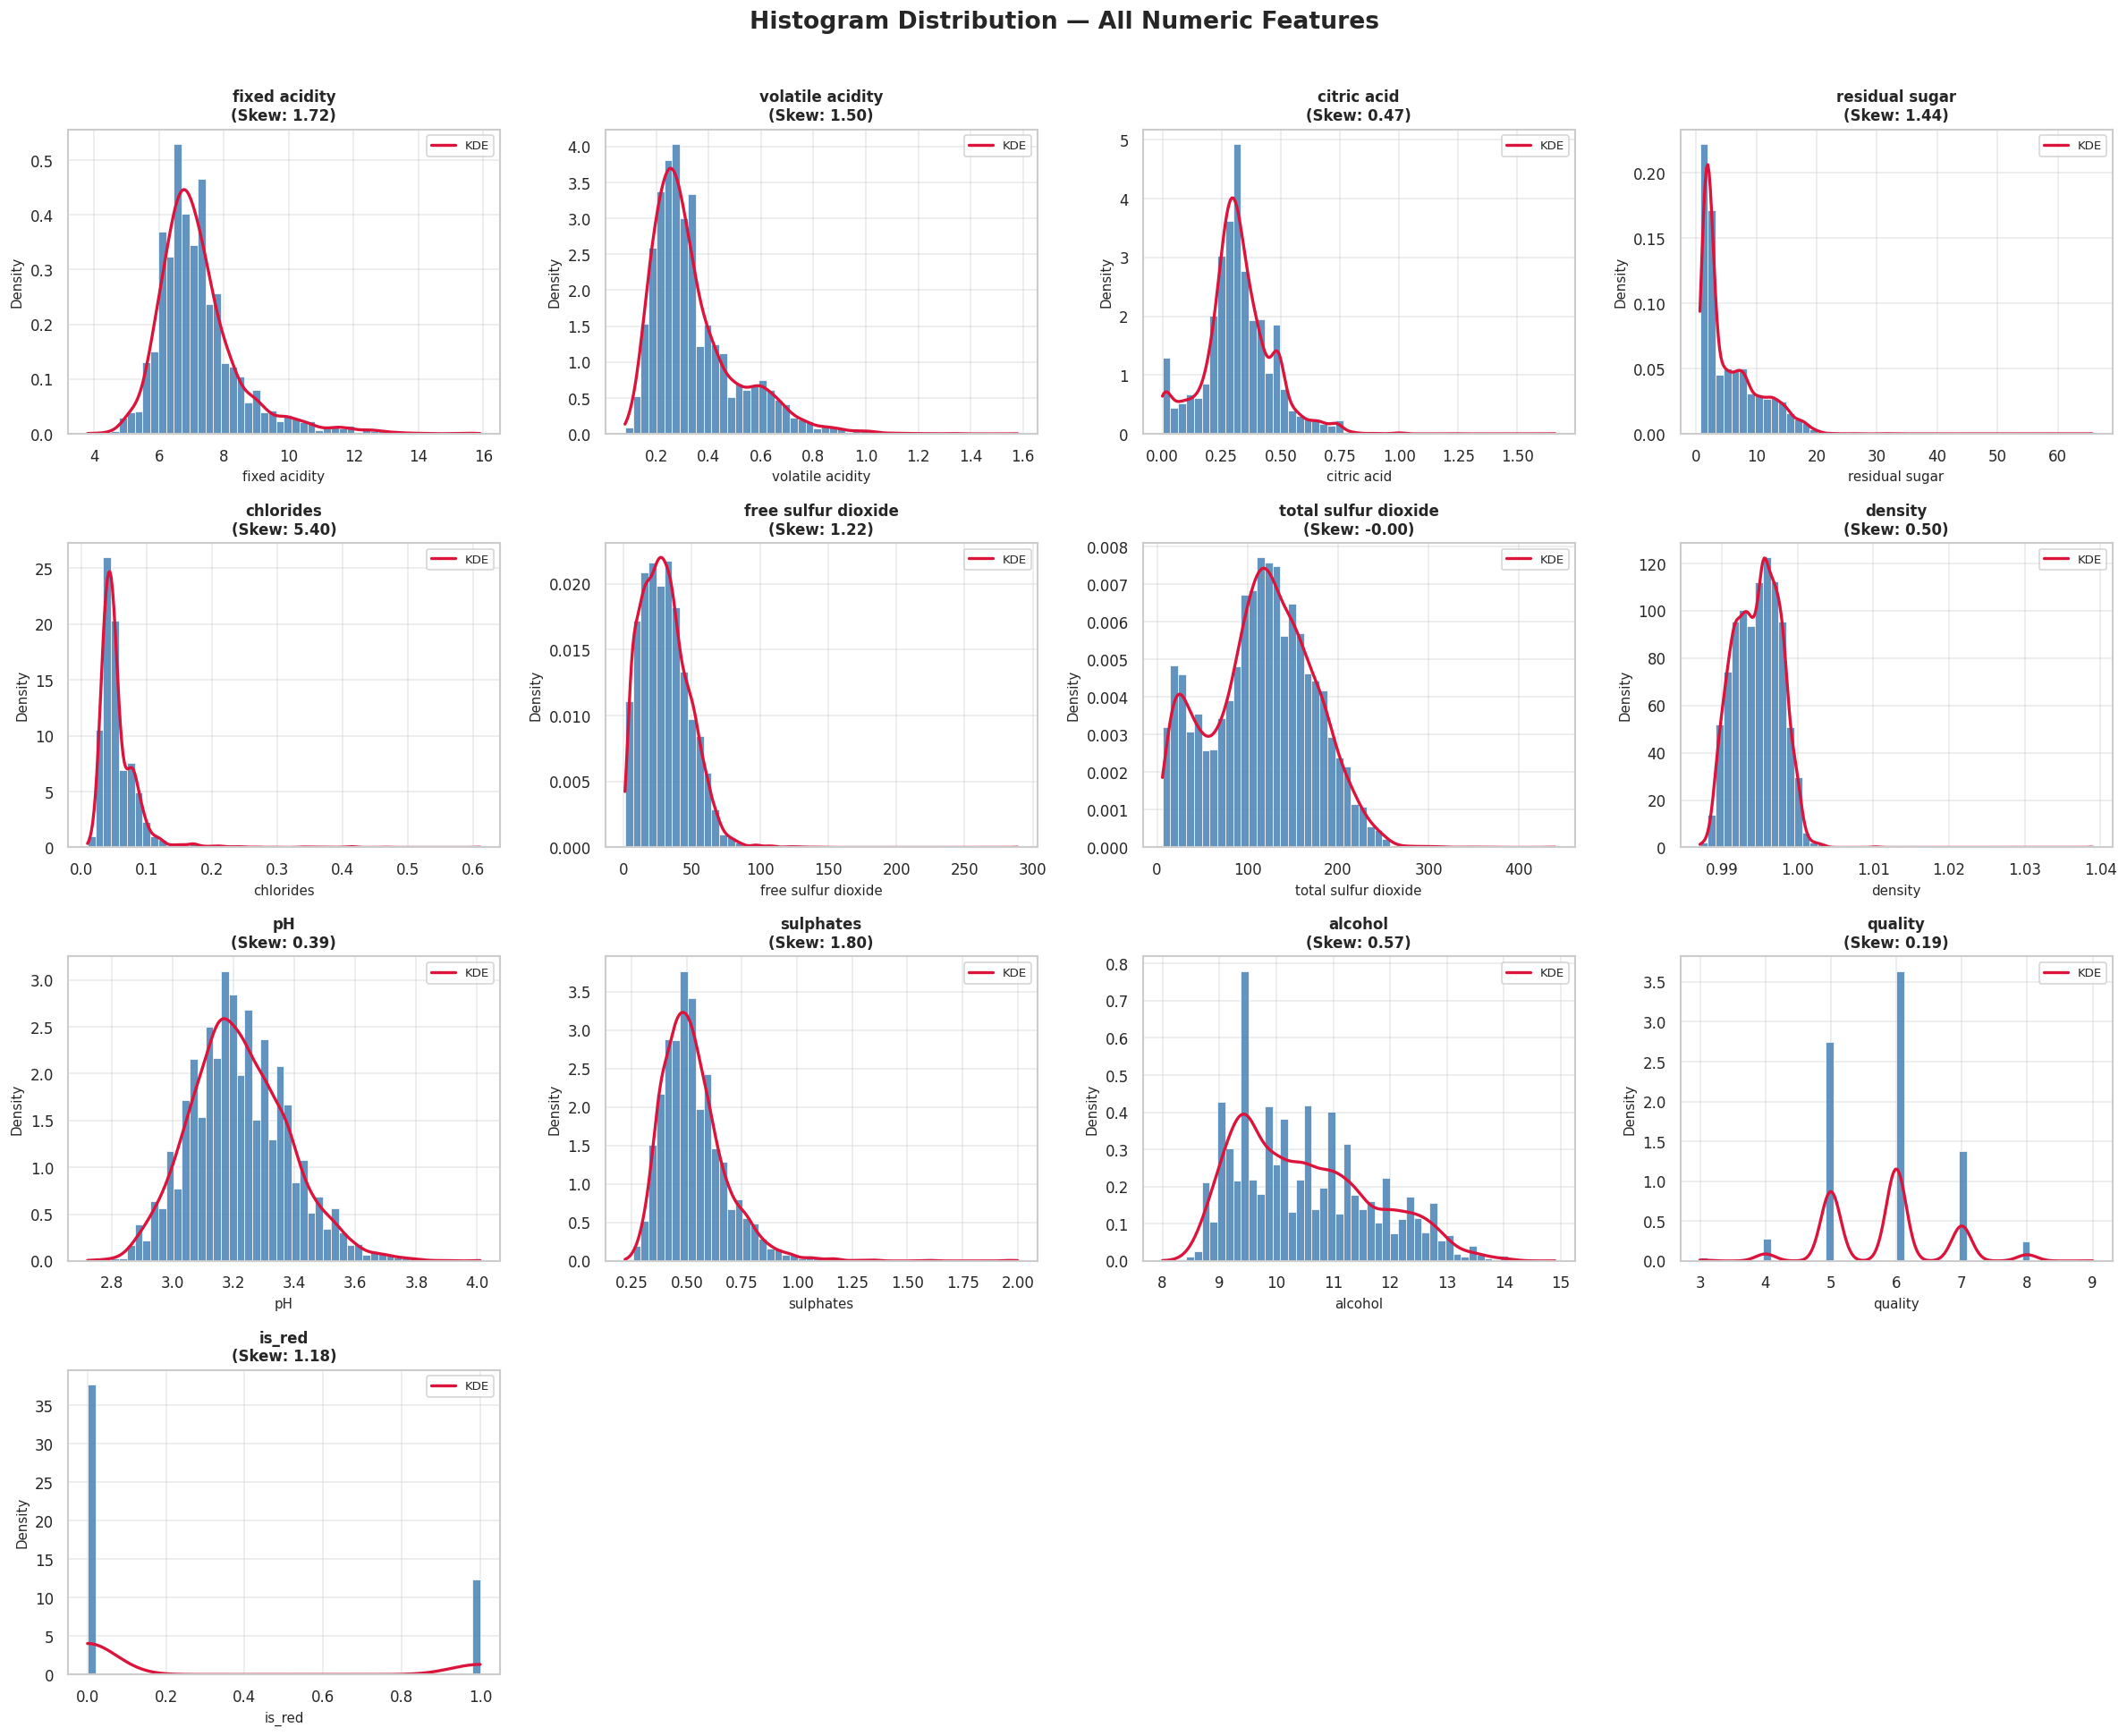

Histograms with KDE overlays generated.


In [ ]:
# STEP 4.2 — HISTOGRAMS FOR ALL NUMERIC VARIABLES
# Visualise the frequency distribution of every numeric feature to assess skewness, modality, and range.

# Select all numeric columns excluding the binary and target columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

n_cols  = 4
n_rows  = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
fig.suptitle('Histogram Distribution — All Numeric Features', fontsize=16, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    skewness = df[col].skew()
    # Use KDE overlay for a smooth density estimate alongside the histogram
    axes[i].hist(df[col], bins=50, color='steelblue', edgecolor='white',
                 linewidth=0.5, alpha=0.85, density=True)

    # Add a KDE overlay
    from scipy.stats import gaussian_kde
    kde = gaussian_kde(df[col].dropna())
    x_range = np.linspace(df[col].min(), df[col].max(), 300)
    axes[i].plot(x_range, kde(x_range), color='crimson', linewidth=2, label='KDE')

    axes[i].set_title(f'{col}\n(Skew: {skewness:.2f})', fontsize=10, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel('Density', fontsize=9)
    axes[i].legend(fontsize=8)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('histograms_all_features.png', bbox_inches='tight', dpi=150)
plt.show()
print("Histograms with KDE overlays generated.")

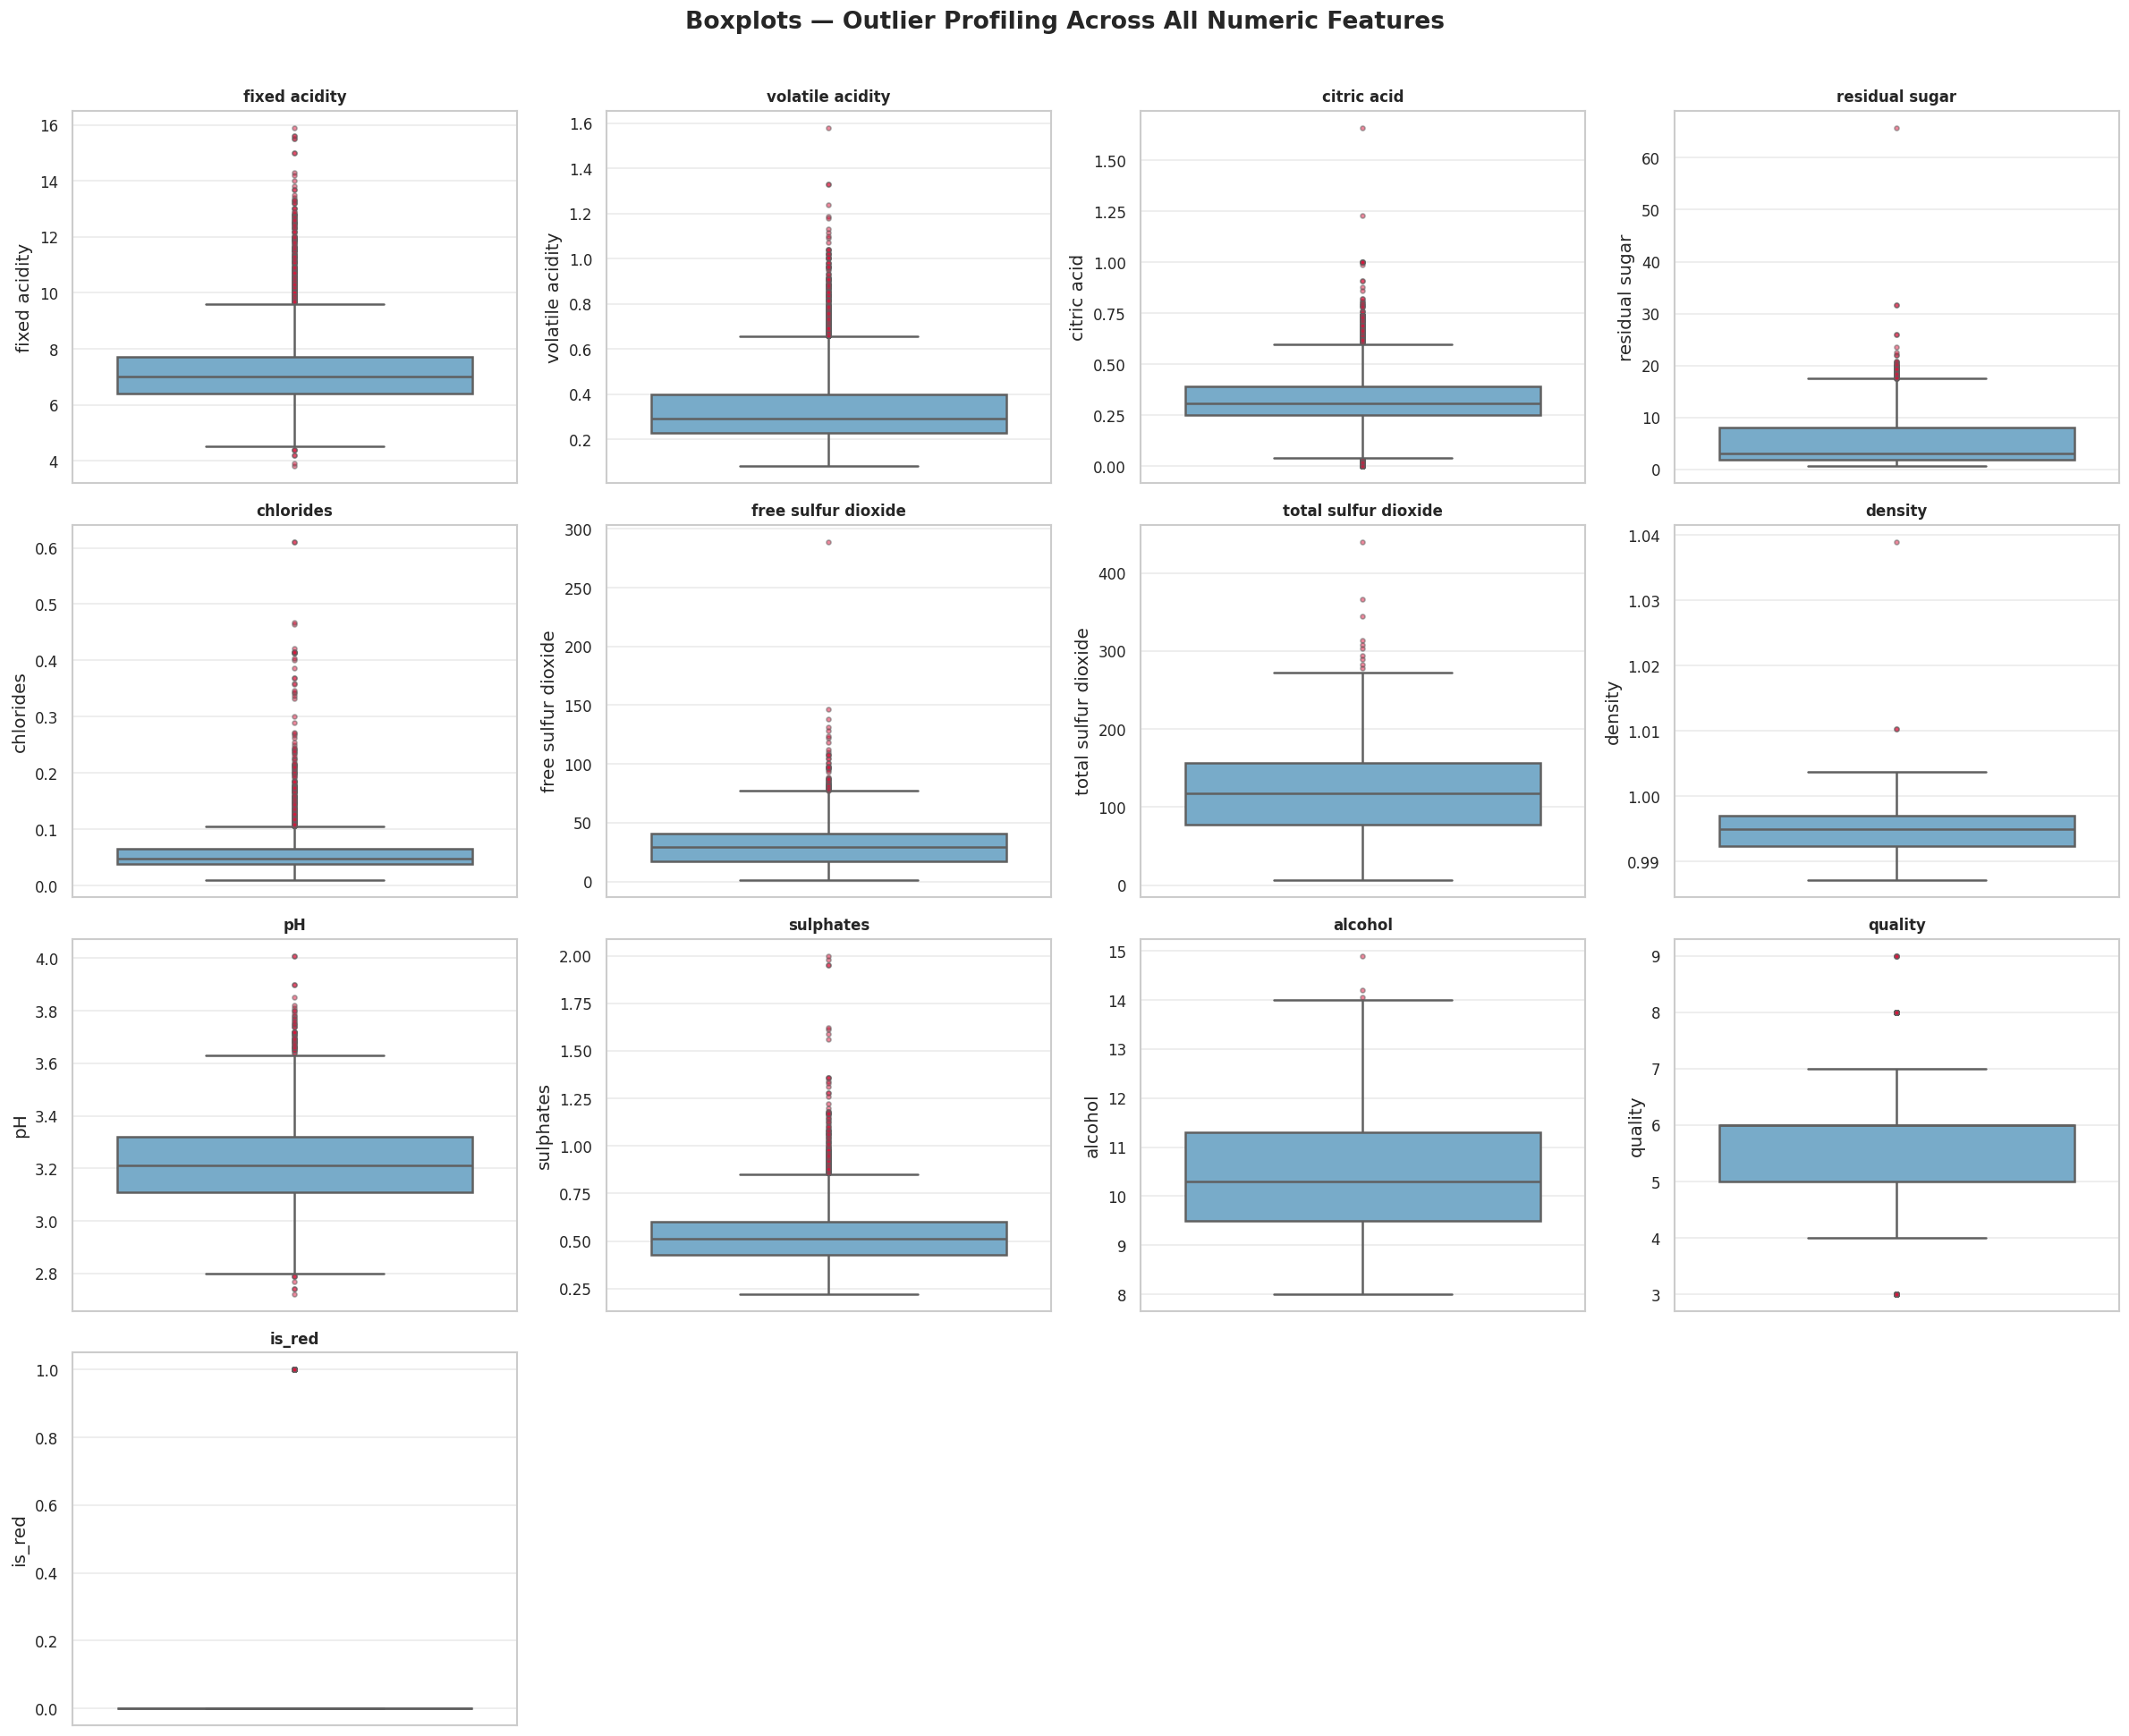

Boxplots generated. Outliers visible as red scatter points above/below whiskers.


In [ ]:
# STEP 4.3 — BOXPLOTS FOR ALL VARIABLES
# Visualise the IQR spread and outlier presence across all features.

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
fig.suptitle('Boxplots — Outlier Profiling Across All Numeric Features', fontsize=16, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=df, y=col,
        ax=axes[i],
        color='#6baed6',
        flierprops=dict(marker='o', markerfacecolor='crimson', markersize=3, alpha=0.5),
        linewidth=1.5
    )
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('boxplots_all_features.png', bbox_inches='tight', dpi=150)
plt.show()
print("Boxplots generated. Outliers visible as red scatter points above/below whiskers.")

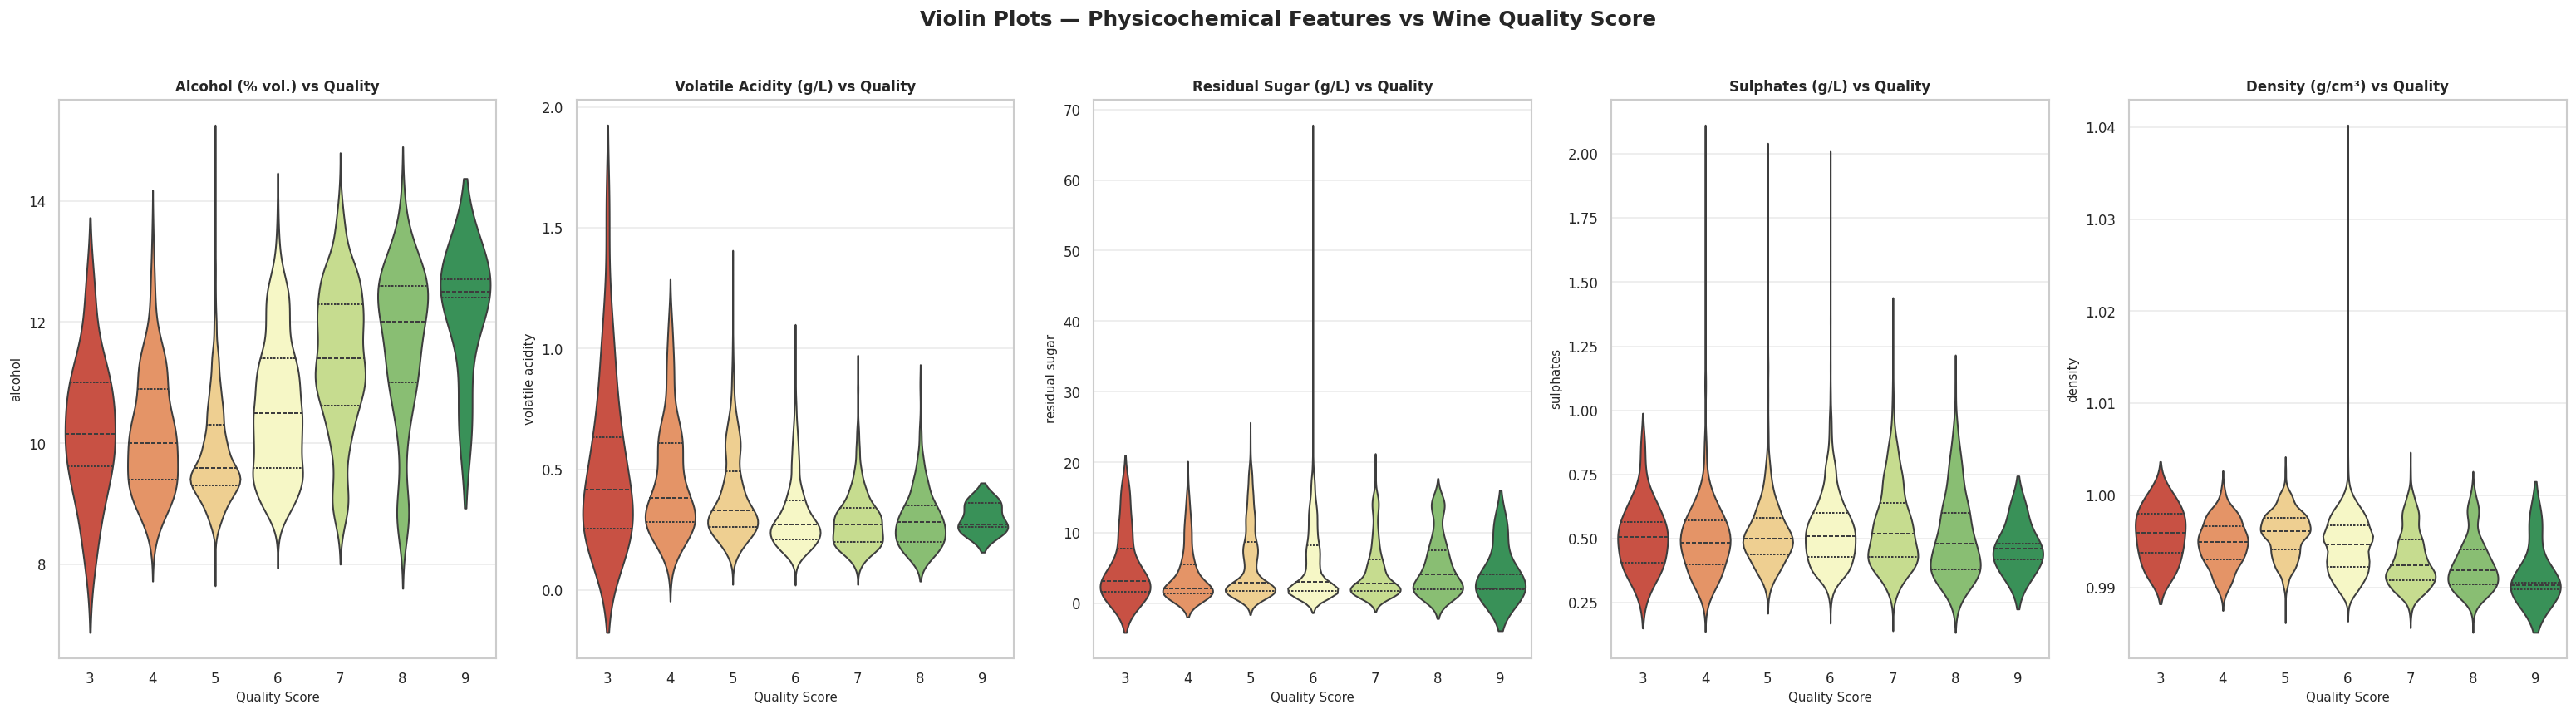

Violin plots generated.


In [ ]:
# STEP 4.4 — VIOLIN PLOTS: KEY FEATURES VS QUALITY
# Violin plots combine the informational value of a boxplot with a KDE,
# revealing how feature distributions shift across quality classes.
# Five features are selected based on their known viticulture relevance.

violin_features = ['alcohol', 'volatile acidity', 'residual sugar', 'sulphates', 'density']
violin_titles   = [
    'Alcohol (% vol.) vs Quality',
    'Volatile Acidity (g/L) vs Quality',
    'Residual Sugar (g/L) vs Quality',
    'Sulphates (g/L) vs Quality',
    'Density (g/cm³) vs Quality'
]

fig, axes = plt.subplots(1, 5, figsize=(26, 7))
fig.suptitle('Violin Plots — Physicochemical Features vs Wine Quality Score',
             fontsize=15, fontweight='bold', y=1.02)

quality_order = sorted(df['quality'].unique())
palette       = sns.color_palette('RdYlGn', n_colors=len(quality_order))

for i, (feat, title) in enumerate(zip(violin_features, violin_titles)):
    sns.violinplot(
        data=df,
        x='quality',
        y=feat,
        order=quality_order,
        palette=palette,
        inner='quartile',   # Show quartile lines inside each violin
        linewidth=1.2,
        ax=axes[i]
    )
    axes[i].set_title(title, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Quality Score', fontsize=9)
    axes[i].set_ylabel(feat, fontsize=9)

plt.tight_layout()
plt.savefig('violin_plots_features_vs_quality.png', bbox_inches='tight', dpi=150)
plt.show()
print("Violin plots generated.")

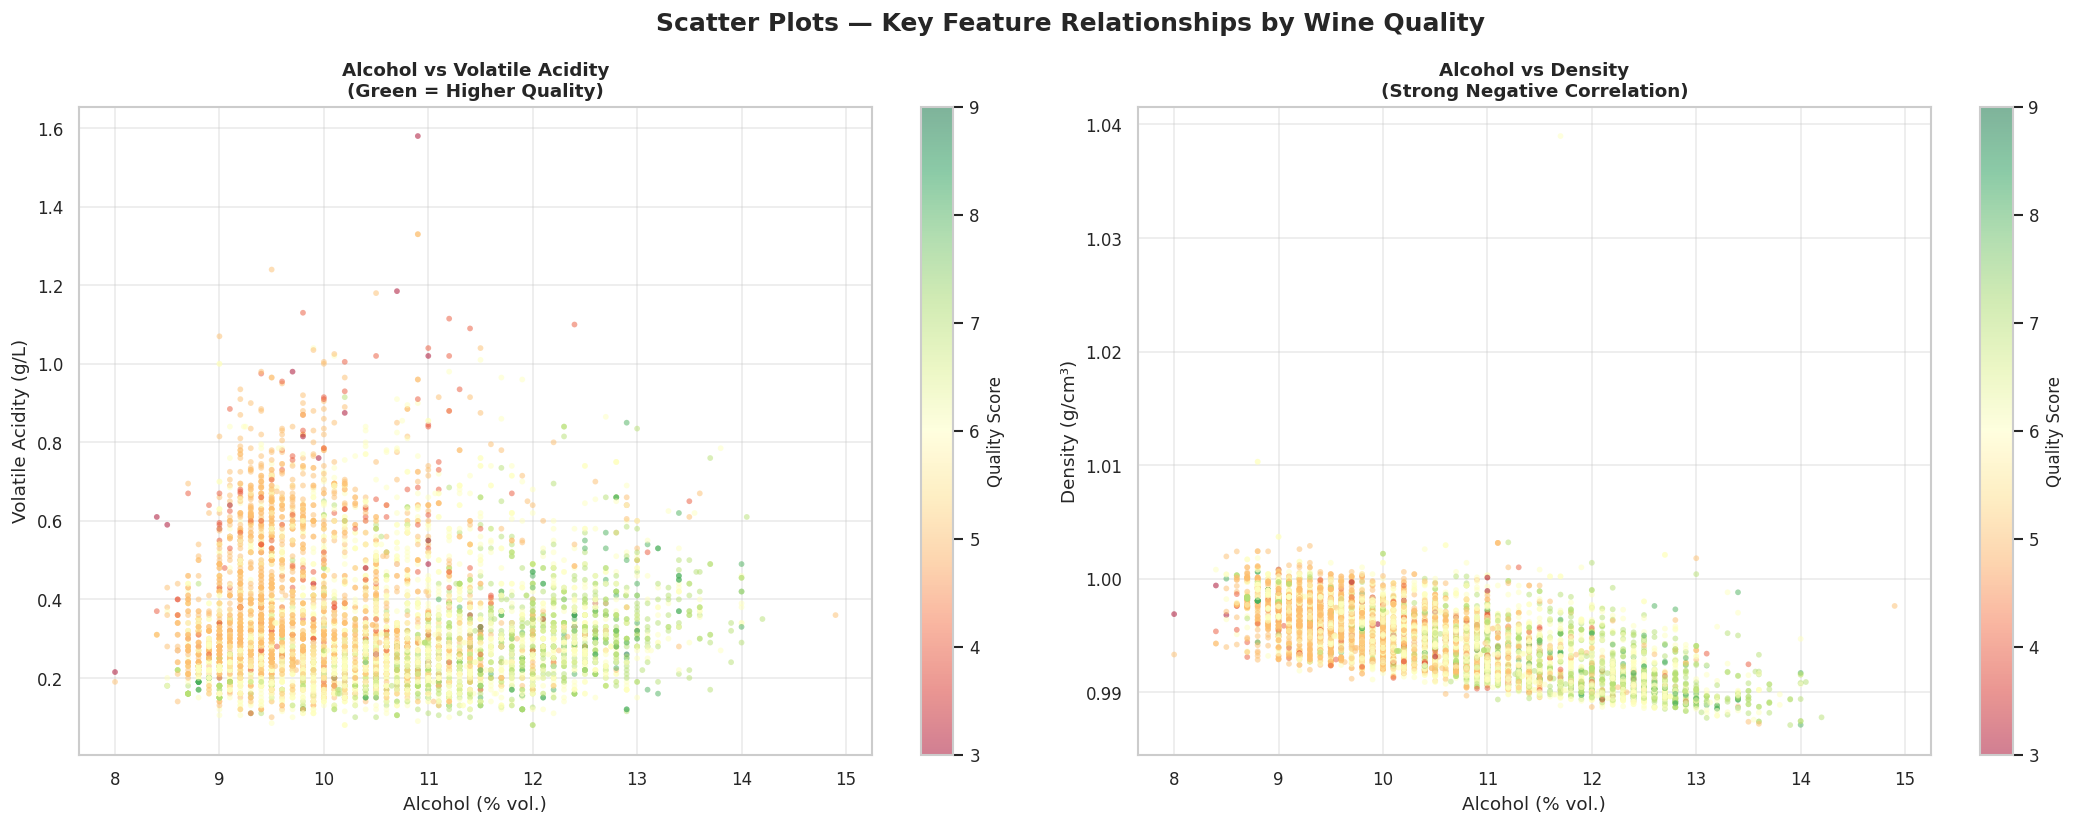

Scatter plots generated.


In [ ]:
# STEP 4.5 — SCATTER PLOTS: ALCOHOL vs VOLATILE ACIDITY (coloured by quality)
# Explore the joint relationship of the two most predictive features
# with quality class as the colour dimension.

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Scatter Plots — Key Feature Relationships by Wine Quality',
             fontsize=15, fontweight='bold')

# --- Scatter: Alcohol vs Volatile Acidity ---
scatter1 = axes[0].scatter(
    df['alcohol'], df['volatile acidity'],
    c=df['quality'], cmap='RdYlGn', alpha=0.5, s=12, edgecolors='none'
)
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Quality Score', fontsize=10)
axes[0].set_xlabel('Alcohol (% vol.)', fontsize=11)
axes[0].set_ylabel('Volatile Acidity (g/L)', fontsize=11)
axes[0].set_title('Alcohol vs Volatile Acidity\n(Green = Higher Quality)', fontsize=11, fontweight='bold')

# --- Scatter: Density vs Alcohol ---
scatter2 = axes[1].scatter(
    df['alcohol'], df['density'],
    c=df['quality'], cmap='RdYlGn', alpha=0.5, s=12, edgecolors='none'
)
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Quality Score', fontsize=10)
axes[1].set_xlabel('Alcohol (% vol.)', fontsize=11)
axes[1].set_ylabel('Density (g/cm³)', fontsize=11)
axes[1].set_title('Alcohol vs Density\n(Strong Negative Correlation)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('scatter_plots.png', bbox_inches='tight', dpi=150)
plt.show()
print("Scatter plots generated.")

# Step 5 — Outlier Detection and Profiling

IQR OUTLIER DETECTION REPORT — DESCRIPTIVE DATA AUDIT


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,residual sugar,1.800,8.100,6.300,-7.6500,17.5500,118,1.8162
1,total sulfur dioxide,77.000,156.000,79.000,-41.5000,274.5000,10,0.1539
2,chlorides,0.038,0.065,0.027,-0.0025,0.1055,286,4.4020


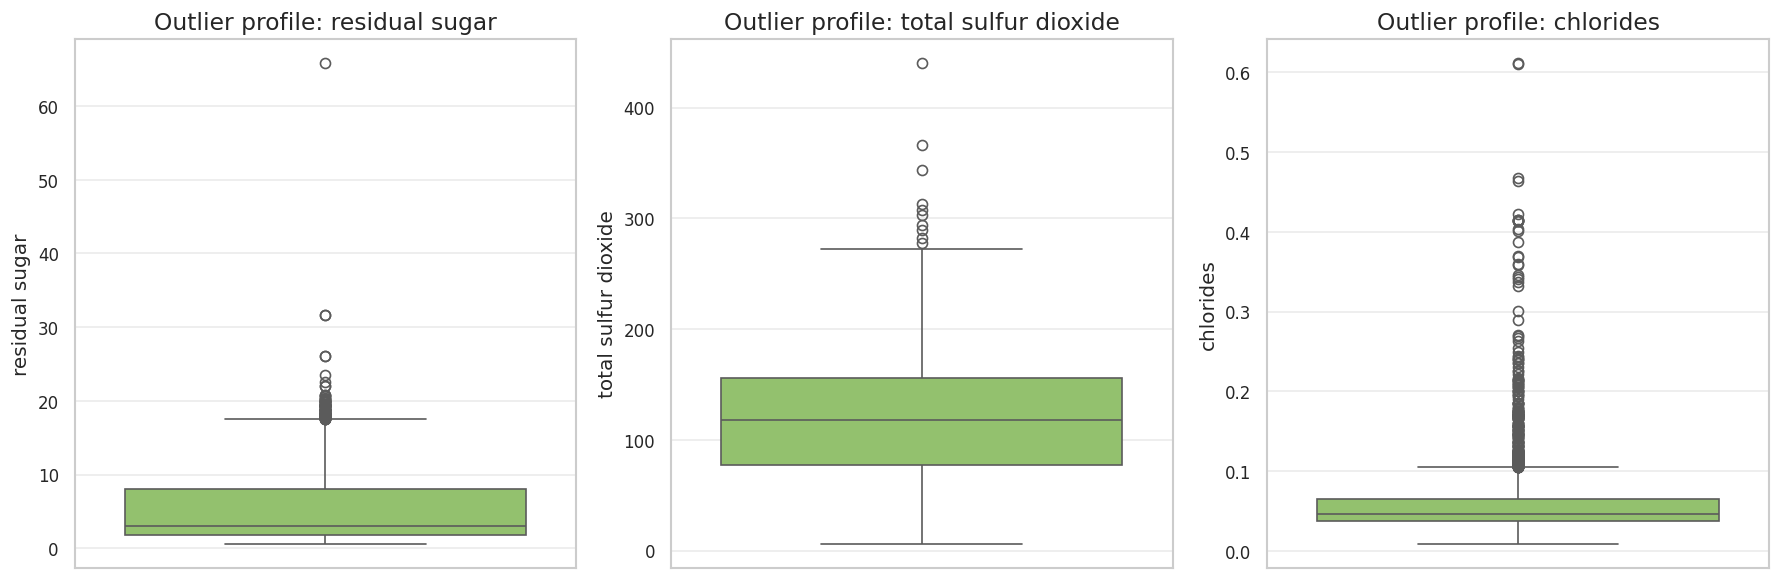

In [ ]:
# This section reports IQR outliers only.
# IQR limits are learned later inside the preprocessing pipeline, using each
# training fold only, and are then applied to that fold's validation data.

outlier_cols = ['residual sugar', 'total sulfur dioxide', 'chlorides']

def detect_iqr_outliers(dataframe, column):
    """Return IQR statistics and the number of observations outside the bounds."""
    q1 = dataframe[column].quantile(0.25)
    q3 = dataframe[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((dataframe[column] < lower_bound) | (dataframe[column] > upper_bound)).sum()
    return q1, q3, iqr, lower_bound, upper_bound, int(count)

outlier_rows = []
for column in outlier_cols:
    q1, q3, iqr, lower, upper, count = detect_iqr_outliers(df, column)
    outlier_rows.append({
        'Column': column,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': count,
        'Outlier Percentage': count / len(df) * 100
    })

outlier_report = pd.DataFrame(outlier_rows).round(4)
print("IQR OUTLIER DETECTION REPORT — DESCRIPTIVE DATA AUDIT")
display(outlier_report)

fig, axes = plt.subplots(1, len(outlier_cols), figsize=(15, 5))
for ax, column in zip(axes, outlier_cols):
    sns.boxplot(data=df, y=column, ax=ax, color='#91cf60')
    ax.set_title(f'Outlier profile: {column}')
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig('outlier_profile_original_data.png', dpi=300, bbox_inches='tight')
plt.show()

# Step 6 — Advanced Feature Engineering

ENGINEERED FEATURE SUMMARY STATISTICS


,Free_to_Total_SO2_Ratio,Total_Acidity_Index
count,6497.00000,6497.00000
mean,0.28677,2.35748
std,0.12464,0.45990
min,0.02273,1.09600
25%,0.20207,2.07165
50%,0.26977,2.27635
75%,0.34884,2.54799
max,0.85714,5.56336


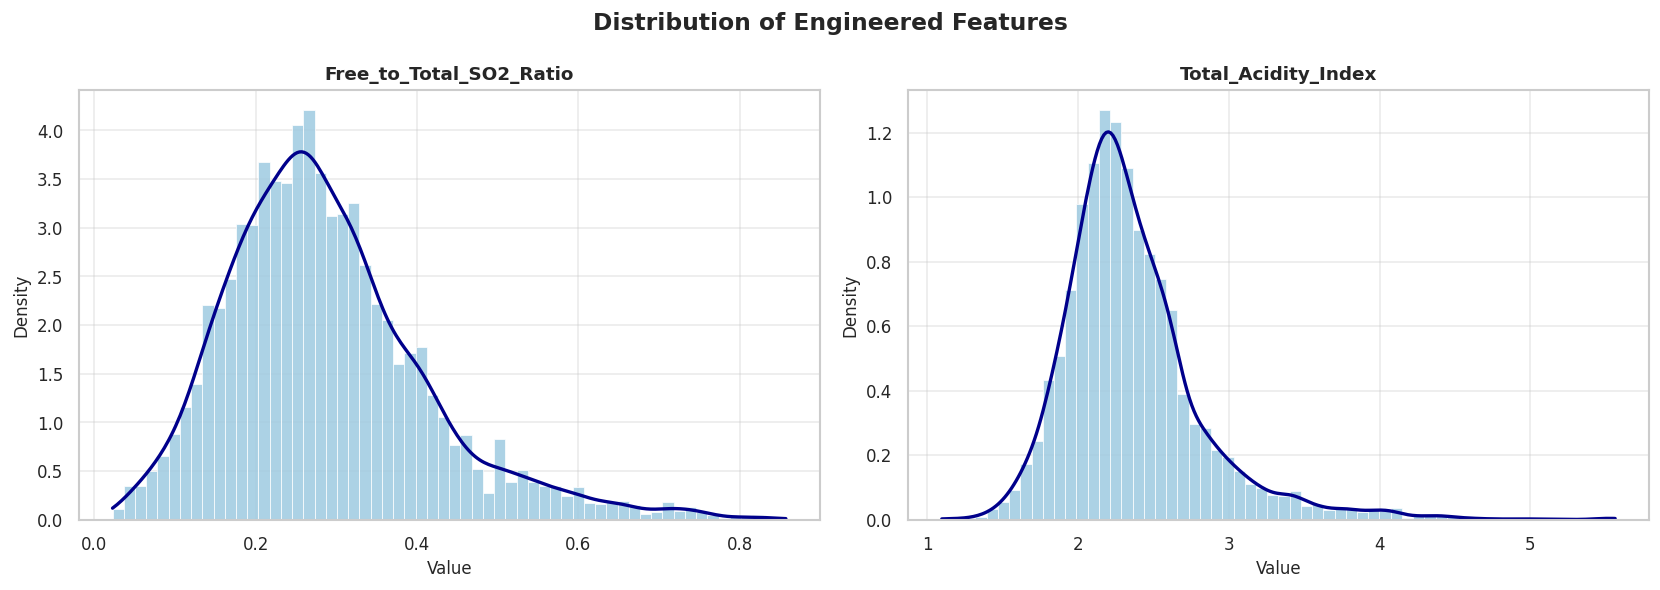


Engineered features added. Dataset now has 15 columns.


In [ ]:
# Two new features are derived from existing physicochemical measurements
# based on viticulture science principles.

# --- Feature 1: Free_to_Total_SO2_Ratio ---
# Scientific Rationale:
# Free SO2 is the active antimicrobial and antioxidant form of sulfur dioxide.
# Total SO2 includes both the free and bound forms.
# The ratio captures oxidation resistance efficiency — wines where the free
# fraction represents a higher proportion of total SO2 have better
# antimicrobial protection per unit of preservative used.
# Division safety: replace any zero total SO2 values with NaN, then fill with 0.

df['Free_to_Total_SO2_Ratio'] = np.where(
    df['total sulfur dioxide'] > 0,
    df['free sulfur dioxide'] / df['total sulfur dioxide'],
    0.0  # Assign 0 if total SO2 is zero to avoid division by zero
)

# --- Feature 2: Total_Acidity_Index ---
# Scientific Rationale:
# Fixed acidity (tartaric acid) and volatile acidity (acetic acid) together
# constitute the overall acid load of the wine. Normalising this combined
# acidity against pH produces an index that captures the true perceived
# sourness and overall flavour balance of the wine.
# A higher index indicates a sharp, acidic wine; lower values suggest
# a rounder, more balanced palate.

df['Total_Acidity_Index'] = (df['fixed acidity'] + df['volatile acidity']) / df['pH']

# --- Descriptive Statistics for New Features ---
engineered_features = ['Free_to_Total_SO2_Ratio', 'Total_Acidity_Index']

print("ENGINEERED FEATURE SUMMARY STATISTICS")
print("=" * 55)
display(df[engineered_features].describe().round(5))

# --- Visualise distributions of the engineered features ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution of Engineered Features', fontsize=14, fontweight='bold')

for i, feat in enumerate(engineered_features):
    axes[i].hist(df[feat], bins=60, color='#9ecae1', edgecolor='white', linewidth=0.5, density=True, alpha=0.85)
    kde = gaussian_kde(df[feat].dropna())
    xr = np.linspace(df[feat].min(), df[feat].max(), 300)
    axes[i].plot(xr, kde(xr), color='darkblue', linewidth=2)
    axes[i].set_title(feat, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Value', fontsize=10)
    axes[i].set_ylabel('Density', fontsize=10)

plt.tight_layout()
plt.savefig('engineered_features_distribution.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nEngineered features added. Dataset now has {df.shape[1]} columns.")

# Step 7 — Feature and Target Preparation

In [ ]:
# Feature engineering is row-wise
# Duplicate predictor rows are grouped so identical predictor records cannot appear
# in both the training and testing sets.

FEATURE_COLUMNS = [column for column in df.columns if column != 'quality']
X = df[FEATURE_COLUMNS].copy()
y = df['quality'].astype(int).copy()
QUALITY_LABELS = sorted(y.unique())
MINORITY_LABELS = [label for label in [3, 4, 8, 9] if label in QUALITY_LABELS]

print(f"Dataset rows: {len(df):,}")
print(f"Predictor columns: {X.shape[1]}")
print(f"Quality classes: {QUALITY_LABELS}")

# Exact duplicate rows and duplicate predictor patterns are both audited.
# Rows are retained; grouped splitting prevents repeated predictor patterns
# from crossing training/testing partitions or cross-validation folds.
exact_duplicate_count = int(df.duplicated().sum())
predictor_duplicate_count = int(X.duplicated().sum())
print(f"Exact duplicate records: {exact_duplicate_count:,}")
print(f"Repeated predictor patterns: {predictor_duplicate_count:,}")

# Group rows with identical predictor values. This retains the original records
# while preventing the same predictor pattern from crossing train/test or CV folds.
group_ids, unique_groups = pd.factorize(pd.MultiIndex.from_frame(X), sort=False)
print(f"Unique predictor groups: {len(unique_groups):,}")

Dataset rows: 6,497
Predictor columns: 14
Quality classes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Exact duplicate records: 1,177
Repeated predictor patterns: 1,177
Unique predictor groups: 5,320


# Step 8 — Leakage-Safe 80:20 Train-Test Split

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
train_indices, test_indices = next(
    outer_cv.split(X, y, groups=group_ids)
)

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()
y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()
groups_train = group_ids[train_indices]

# Verify there is no overlap of predictor groups across the split.
train_group_set = set(groups_train)
test_group_set = set(group_ids[test_indices])
assert train_group_set.isdisjoint(test_group_set), "Duplicate predictor groups cross the split."
assert len(X_train) + len(X_test) == len(X), "Split row count does not match source data."

print("TRAIN-TEST SPLIT")
print(f"Training: {len(X_train):,} ({len(X_train)/len(X):.1%})")
print(f"Testing : {len(X_test):,} ({len(X_test)/len(X):.1%})")
print(f"Shared predictor groups across split: {len(train_group_set.intersection(test_group_set))}")

split_comparison = pd.DataFrame({
    'Full Dataset (%)': y.value_counts(normalize=True) * 100,
    'Training (%)': y_train.value_counts(normalize=True) * 100,
    'Testing (%)': y_test.value_counts(normalize=True) * 100
}).sort_index().round(2)
display(split_comparison)

TRAIN-TEST SPLIT
Training: 5,189 (79.9%)
Testing : 1,308 (20.1%)
Shared predictor groups across split: 0


,Full Dataset (%),Training (%),Testing (%)
quality,,,
3,0.46,0.46,0.46
4,3.32,3.39,3.06
5,32.91,32.99,32.57
6,43.65,43.67,43.58
7,16.61,16.30,17.81
8,2.97,3.08,2.52
9,0.08,0.10,NaN


# Step 9 — Leakage-Safe Preprocessing and Model Validation

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, make_scorer
)
from scipy.stats import randint, uniform

class IQRWinsorizer(BaseEstimator, TransformerMixin):
    """Fit IQR caps on the current training fold only, then apply them."""
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_frame = pd.DataFrame(X).copy()
        self.feature_names_in_ = np.asarray(X_frame.columns, dtype=object)
        self.columns_ = list(self.columns or [])
        self.bounds_ = {}
        for column in self.columns_:
            if column in X_frame.columns:
                q1 = X_frame[column].quantile(0.25)
                q3 = X_frame[column].quantile(0.75)
                iqr = q3 - q1
                self.bounds_[column] = (
                    q1 - self.factor * iqr,
                    q3 + self.factor * iqr
                )
        return self

    def transform(self, X):
        X_frame = pd.DataFrame(X).copy()
        for column, (lower, upper) in self.bounds_.items():
            X_frame[column] = X_frame[column].clip(lower=lower, upper=upper)
        return X_frame

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None
                          else self.feature_names_in_, dtype=object)

# Encode target labels once for XGBoost. This only maps class names to integers;
# it does not estimate any feature transformation.
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
encoded_classes = np.arange(len(label_encoder.classes_))
encoded_minority_labels = label_encoder.transform(MINORITY_LABELS)

def build_pipeline(classifier):
    return Pipeline(steps=[
        ('winsorizer', IQRWinsorizer(columns=outlier_cols, factor=1.5)),
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

# Use the same five grouped, stratified folds for the baseline and all models.
inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

scoring_original = {
    'accuracy': make_scorer(accuracy_score),
    'weighted_f1': make_scorer(f1_score, average='weighted', zero_division=0),
    'macro_f1': make_scorer(
        f1_score, labels=QUALITY_LABELS, average='macro', zero_division=0
    ),
    'minority_f1': make_scorer(
        f1_score, labels=MINORITY_LABELS, average='macro', zero_division=0
    )
}
scoring_encoded = {
    'accuracy': make_scorer(accuracy_score),
    'weighted_f1': make_scorer(f1_score, average='weighted', zero_division=0),
    'macro_f1': make_scorer(
        f1_score, labels=encoded_classes, average='macro', zero_division=0
    ),
    'minority_f1': make_scorer(
        f1_score, labels=encoded_minority_labels,
        average='macro', zero_division=0
    )
}

# Majority-class baseline: a reference point, not a competing tuned model.
baseline_pipeline = Pipeline([
    ('classifier', DummyClassifier(strategy='most_frequent'))
])
baseline_cv = cross_validate(
    baseline_pipeline, X_train, y_train,
    cv=inner_cv, groups=groups_train,
    scoring=scoring_original, n_jobs=-1,
    return_train_score=False
)
cv_rows = [{
    'Model': 'Majority-class baseline',
    'CV Accuracy': np.mean(baseline_cv['test_accuracy']),
    'CV Accuracy SD': np.std(baseline_cv['test_accuracy'], ddof=1),
    'CV Weighted F1': np.mean(baseline_cv['test_weighted_f1']),
    'CV Weighted F1 SD': np.std(baseline_cv['test_weighted_f1'], ddof=1),
    'CV Macro F1': np.mean(baseline_cv['test_macro_f1']),
    'CV Minority F1': np.mean(baseline_cv['test_minority_f1'])
}]

# Step 10 — Model Training and Single Model Comparison


Tuning Random Forest using five-fold grouped stratified CV...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Random Forest best CV weighted F1: 0.5439
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 20, 'classifier__class_weight': 'balanced'}

Tuning XGBoost using five-fold grouped stratified CV...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
XGBoost best CV weighted F1: 0.5364
Best parameters: {'classifier__subsample': 1.0, 'classifier__reg_lambda': 2, 'classifier__reg_alpha': 0.1, 'classifier__n_estimators': 100, 'classifier__max_depth': 7, 'classifier__learning_rate': 0.2, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}

Tuning LightGBM using five-fold grouped stratified CV...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
LightGBM best CV weighted F1: 0.5324
Best parameters: {'classifier__sub

,Model,CV Accuracy,CV Accuracy SD,CV Weighted F1,CV Weighted F1 SD,CV Macro F1,CV Minority F1,Test Accuracy,Test Weighted F1,Test Macro F1
0,Random Forest,0.5610,0.0109,0.5439,0.0150,0.2773,0.0755,0.5734,0.5590,0.2795
1,XGBoost,0.5549,0.0145,0.5364,0.0189,0.2551,0.0410,0.5520,0.5356,0.2590
2,LightGBM,0.5483,0.0124,0.5324,0.0131,0.2618,0.0568,0.5581,0.5433,0.2700
3,Majority-class baseline,0.4369,0.0178,0.2658,0.0184,0.0868,0.0000,0.4358,0.2645,0.0867



MINORITY-CLASS HELD-OUT TEST PERFORMANCE


,Model,Quality Class,Test Precision,Test Recall,Test F1,Test Support
0,Majority-class baseline,3,0.0000,0.0000,0.0000,6
1,Majority-class baseline,4,0.0000,0.0000,0.0000,40
2,Majority-class baseline,8,0.0000,0.0000,0.0000,33
3,Majority-class baseline,9,0.0000,0.0000,0.0000,0
4,Random Forest,3,0.0000,0.0000,0.0000,6
5,Random Forest,4,0.4545,0.1250,0.1961,40
6,Random Forest,8,0.2500,0.0303,0.0541,33
7,Random Forest,9,0.0000,0.0000,0.0000,0
8,XGBoost,3,0.0000,0.0000,0.0000,6
9,XGBoost,4,0.3750,0.0750,0.1250,40



Selected model based on CV weighted F1: Random Forest
Selected model CV weighted F1: 0.5439

CLASSIFICATION REPORT — SELECTED MODEL, ALL QUALITY CLASSES
              precision    recall  f1-score   support

           3     0.0000    0.0000    0.0000         6
           4     0.4545    0.1250    0.1961        40
           5     0.6210    0.6385    0.6296       426
           6     0.5551    0.6544    0.6006       570
           7     0.5410    0.4249    0.4760       233
           8     0.2500    0.0303    0.0541        33
           9     0.0000    0.0000    0.0000         0

    accuracy                         0.5734      1308
   macro avg     0.3459    0.2676    0.2795      1308
weighted avg     0.5607    0.5734    0.5590      1308



,precision,recall,f1-score,support
3,0.0000,0.0000,0.0000,6.0000
4,0.4545,0.1250,0.1961,40.0000
5,0.6210,0.6385,0.6296,426.0000
6,0.5551,0.6544,0.6006,570.0000
7,0.5410,0.4249,0.4760,233.0000
8,0.2500,0.0303,0.0541,33.0000
9,0.0000,0.0000,0.0000,0.0000
accuracy,0.5734,0.5734,0.5734,0.5734
macro avg,0.3459,0.2676,0.2795,1308.0000
weighted avg,0.5607,0.5734,0.5590,1308.0000


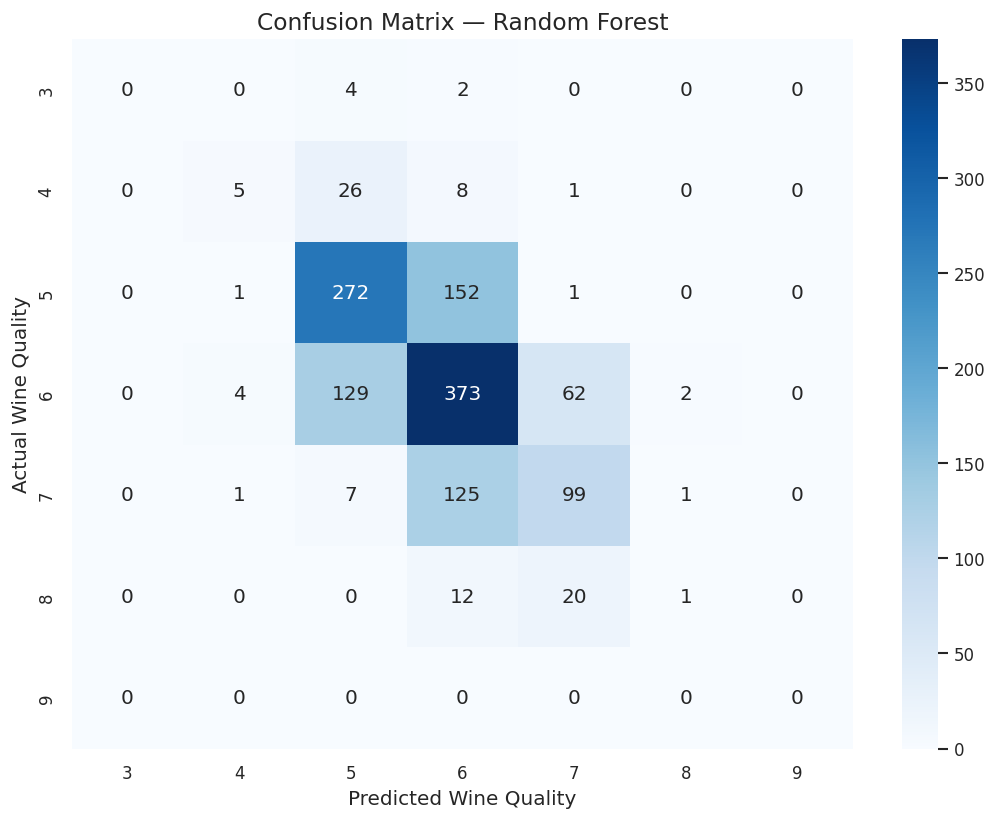

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


model_specs = {
    'Random Forest': {
        'estimator': build_pipeline(
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
        ),
        'params': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__max_depth': [None, 10, 20],
            'classifier__min_samples_split': [2, 5, 10],
            'classifier__min_samples_leaf': [1, 2, 4],
            'classifier__max_features': ['sqrt', 'log2'],
            'classifier__class_weight': ['balanced', None]
        },
        'target': y_train,
        'scoring': scoring_original
    },
    'XGBoost': {
        'estimator': build_pipeline(
            XGBClassifier(
                objective='multi:softprob',
                num_class=len(encoded_classes),
                eval_metric='mlogloss',
                random_state=RANDOM_STATE,
                verbosity=0,
                tree_method='hist',
                n_jobs=1
            )
        ),
        'params': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__learning_rate': [0.05, 0.10, 0.20],
            'classifier__max_depth': [3, 5, 7],
            'classifier__subsample': [0.8, 1.0],
            'classifier__colsample_bytree': [0.8, 1.0],
            'classifier__gamma': [0, 0.1],
            'classifier__reg_alpha': [0, 0.1],
            'classifier__reg_lambda': [1, 2]
        },
        'target': y_train_encoded,
        'scoring': scoring_encoded
    },
    'LightGBM': {
        'estimator': build_pipeline(
            LGBMClassifier(
                objective='multiclass',
                random_state=RANDOM_STATE,
                verbosity=-1,
                force_col_wise=True,
                n_jobs=1
            )
        ),
        'params': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__learning_rate': [0.05, 0.10, 0.20],
            'classifier__max_depth': [-1, 8, 12],
            'classifier__num_leaves': [31, 50, 70],
            'classifier__min_child_samples': [20, 30],
            'classifier__subsample': [0.8, 1.0],
            'classifier__colsample_bytree': [0.8, 1.0],
            'classifier__reg_alpha': [0, 0.1],
            'classifier__reg_lambda': [0, 1]
        },
        'target': y_train,
        'scoring': scoring_original
    }
}

N_ITER = 15
searches = {}

for model_name, spec in model_specs.items():
    print(f"\nTuning {model_name} using five-fold grouped stratified CV...")
    search = RandomizedSearchCV(
        estimator=spec['estimator'],
        param_distributions=spec['params'],
        n_iter=N_ITER,
        scoring=spec['scoring'],
        refit='weighted_f1',
        cv=inner_cv,
        n_jobs=4,
        random_state=RANDOM_STATE,
        verbose=1,
        error_score='raise',
        return_train_score=False
    )
    search.fit(
        X_train, spec['target'],
        groups=groups_train
    )
    searches[model_name] = search

    result = search.cv_results_
    cv_rows.append({
        'Model': model_name,
        'CV Accuracy': result['mean_test_accuracy'][search.best_index_],
        'CV Accuracy SD': result['std_test_accuracy'][search.best_index_],
        'CV Weighted F1': result['mean_test_weighted_f1'][search.best_index_],
        'CV Weighted F1 SD': result['std_test_weighted_f1'][search.best_index_],
        'CV Macro F1': result['mean_test_macro_f1'][search.best_index_],
        'CV Minority F1': result['mean_test_minority_f1'][search.best_index_]
    })
    print(f"{model_name} best CV weighted F1: {search.best_score_:.4f}")
    print(f"Best parameters: {search.best_params_}")

# Evaluate every model and the baseline on the same untouched held-out test set.
# This creates one consolidated table containing both CV and test metrics.

def original_quality_predictions(model_name, fitted_model, features):
    """Return predictions using the original wine-quality labels (3–9)."""
    raw_predictions = np.asarray(fitted_model.predict(features))
    if model_name == 'XGBoost':
        return label_encoder.inverse_transform(raw_predictions.astype(int))
    return raw_predictions.astype(int)


test_estimators = {'Majority-class baseline': baseline_pipeline}
test_estimators.update({
    name: search.best_estimator_ for name, search in searches.items()
})

# Fit the baseline once on all training data. Tuned model estimators are already
# refitted on all training data by RandomizedSearchCV(refit='weighted_f1').
test_estimators['Majority-class baseline'].fit(X_train, y_train)

predictions_by_model = {}
test_rows = []
minority_test_rows = []

for model_name, fitted_model in test_estimators.items():
    predictions = original_quality_predictions(model_name, fitted_model, X_test)
    predictions_by_model[model_name] = predictions

    test_rows.append({
        'Model': model_name,
        'Test Accuracy': accuracy_score(y_test, predictions),
        'Test Weighted F1': f1_score(y_test, predictions, average='weighted', zero_division=0),
        'Test Macro F1': f1_score(
            y_test, predictions, labels=QUALITY_LABELS,
            average='macro', zero_division=0
        )
    })

    per_class = classification_report(
        y_test, predictions, labels=MINORITY_LABELS,
        output_dict=True, zero_division=0
    )
    for quality_label in MINORITY_LABELS:
        metrics = per_class[str(quality_label)]
        minority_test_rows.append({
            'Model': model_name,
            'Quality Class': quality_label,
            'Test Precision': metrics['precision'],
            'Test Recall': metrics['recall'],
            'Test F1': metrics['f1-score'],
            'Test Support': int(metrics['support'])
        })

# Merge CV and held-out test results into one results table.
test_metrics_df = pd.DataFrame(test_rows)
comparison_df = pd.DataFrame(cv_rows).merge(test_metrics_df, on='Model', how='inner')
comparison_df = comparison_df.sort_values(
    'CV Weighted F1', ascending=False
).reset_index(drop=True)
comparison_df = comparison_df.round(4)

print("\nCONSOLIDATED FIVE-FOLD CV AND HELD-OUT TEST COMPARISON")
display(comparison_df)
comparison_df.to_csv('model_comparison_cv_and_test.csv', index=False)

print("\nMINORITY-CLASS HELD-OUT TEST PERFORMANCE")
minority_test_df = pd.DataFrame(minority_test_rows).round(4)
display(minority_test_df)
minority_test_df.to_csv('minority_class_test_metrics.csv', index=False)

# Select the best classifier using training-only CV weighted F1.
best_model_name = comparison_df.loc[
    comparison_df['Model'] != 'Majority-class baseline', 'Model'
].iloc[0]
best_model = searches[best_model_name].best_estimator_
best_cv_score = searches[best_model_name].best_score_
y_pred = predictions_by_model[best_model_name]

print(f"\nSelected model based on CV weighted F1: {best_model_name}")
print(f"Selected model CV weighted F1: {best_cv_score:.4f}")

# Held-out evaluation details for the selected model.
test_accuracy = accuracy_score(y_test, y_pred)
test_weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
test_macro_f1 = f1_score(
    y_test, y_pred, labels=QUALITY_LABELS, average='macro', zero_division=0
)

print("\nCLASSIFICATION REPORT — SELECTED MODEL, ALL QUALITY CLASSES")
print(classification_report(
    y_test, y_pred, labels=QUALITY_LABELS,
    zero_division=0, digits=4
))
class_report = pd.DataFrame(classification_report(
    y_test, y_pred, labels=QUALITY_LABELS,
    output_dict=True, zero_division=0
)).T
display(class_report.round(4))
class_report.to_csv('selected_model_classification_report.csv')

# Confusion matrix for the selected model.
cm = confusion_matrix(y_test, y_pred, labels=QUALITY_LABELS)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=QUALITY_LABELS, yticklabels=QUALITY_LABELS
)
plt.title(f'Confusion Matrix — {best_model_name}')
plt.xlabel('Predicted Wine Quality')
plt.ylabel('Actual Wine Quality')
plt.tight_layout()
plt.savefig('selected_model_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

#Step 11 — Near-Miss and Ordinal Error Analysis

In [ ]:
# Explicit near-miss analysis: quantify the absolute distance between the
# predicted and actual ordinal quality scores.
absolute_errors = np.abs(y_test.to_numpy() - y_pred)
near_miss_summary = pd.DataFrame([{
    'Test Samples': len(y_test),
    'Exact Predictions': int(np.sum(absolute_errors == 0)),
    'Within 1 Quality Point': int(np.sum(absolute_errors <= 1)),
    'Within 2 Quality Points': int(np.sum(absolute_errors <= 2)),
    'Errors Greater Than 2 Points': int(np.sum(absolute_errors > 2)),
    'Mean Absolute Error': float(np.mean(absolute_errors))
}]).round(4)
print("\nNEAR-MISS / ORDINAL ERROR SUMMARY — SELECTED MODEL")
display(near_miss_summary)
near_miss_summary.to_csv('near_miss_summary.csv', index=False)

error_distribution = pd.DataFrame({
    'Absolute Quality Error': absolute_errors
}).value_counts().sort_index().rename('Number of Predictions').reset_index()
error_distribution['Percentage'] = (
    error_distribution['Number of Predictions'] / len(y_test) * 100
).round(2)
print("\nDISTRIBUTION OF ABSOLUTE QUALITY-PREDICTION ERRORS")
display(error_distribution)
error_distribution.to_csv('near_miss_error_distribution.csv', index=False)


NEAR-MISS / ORDINAL ERROR SUMMARY — SELECTED MODEL


,Test Samples,Exact Predictions,Within 1 Quality Point,Within 2 Quality Points,Errors Greater Than 2 Points,Mean Absolute Error
0,1308,750,1266,1304,4,0.4618



DISTRIBUTION OF ABSOLUTE QUALITY-PREDICTION ERRORS


,Absolute Quality Error,Number of Predictions,Percentage
0,0,750,57.34
1,1,516,39.45
2,2,38,2.91
3,3,4,0.31


# Step 12 — SHAP Explainability for the Selected Model

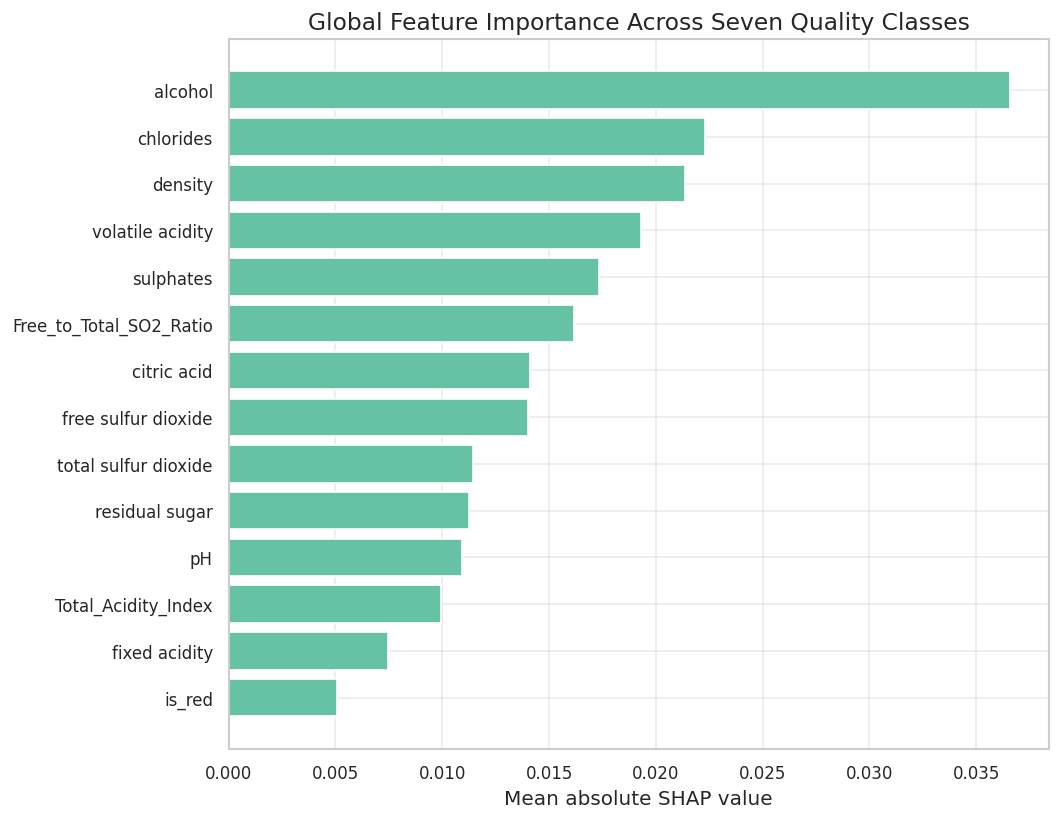

,Feature,Mean Absolute SHAP
10,alcohol,0.03657
4,chlorides,0.02230
7,density,0.02139
1,volatile acidity,0.01931
9,sulphates,0.01734
12,Free_to_Total_SO2_Ratio,0.01617
2,citric acid,0.01409
5,free sulfur dioxide,0.01402
6,total sulfur dioxide,0.01145
3,residual sugar,0.01123


Local explanation — actual quality: 5
Local explanation — predicted quality: 5
Explained quality class: 5
SHAP output scale: raw


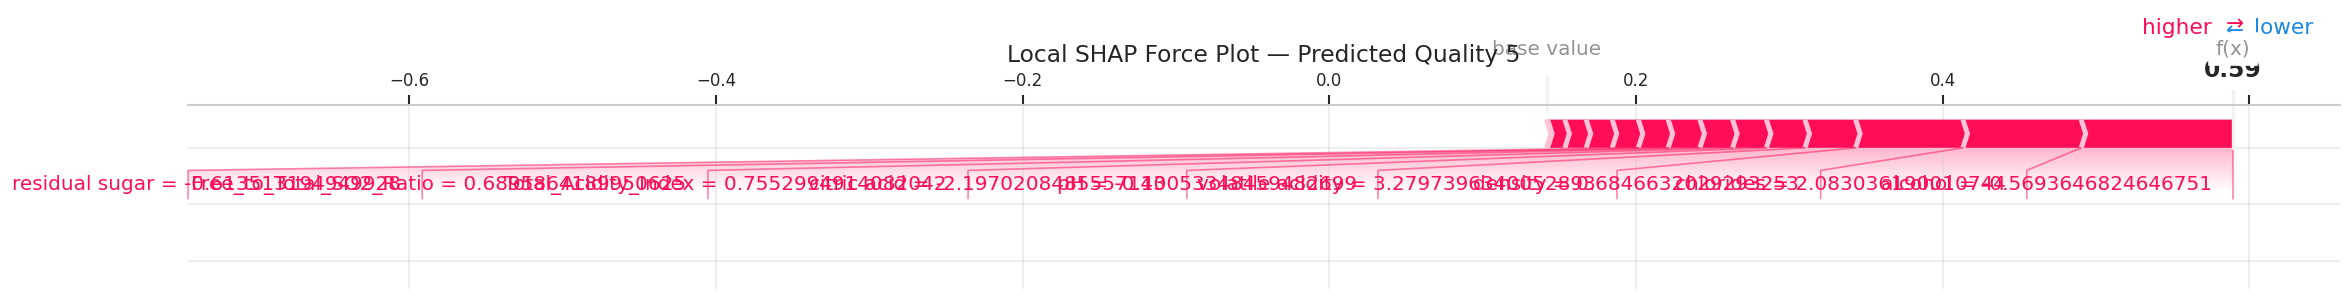

Interpretation: positive SHAP values increase the selected class model output relative to its baseline, while negative values decrease it. The explanation describes this model prediction and does not establish causation.


In [ ]:
# SHAP is run once, only for the selected model. For a multiclass problem,
# each class has its own SHAP output. The global plot aggregates absolute
# contributions across samples and all seven classes. The local plot explains
# one held-out observation for its predicted class.

import shap

classifier = best_model.named_steps['classifier']
X_test_transformed = best_model[:-1].transform(X_test)

# Limit the global explanation sample to keep computation manageable.
SHAP_SAMPLE_SIZE = min(200, len(X_test_transformed))
X_shap = pd.DataFrame(
    X_test_transformed[:SHAP_SAMPLE_SIZE],
    columns=FEATURE_COLUMNS
)
explainer = shap.TreeExplainer(classifier)
shap_values_raw = explainer.shap_values(X_shap)

# Normalize SHAP output to shape: (samples, features, classes).
if isinstance(shap_values_raw, list):
    shap_values_all = np.stack(shap_values_raw, axis=-1)
else:
    shap_values_all = np.asarray(shap_values_raw)

if shap_values_all.ndim != 3:
    raise ValueError(
        f"Expected multiclass SHAP values with 3 dimensions; got {shap_values_all.shape}"
    )
if shap_values_all.shape[1] != len(FEATURE_COLUMNS) and shap_values_all.shape[2] == len(FEATURE_COLUMNS):
    shap_values_all = np.transpose(shap_values_all, (0, 2, 1))
if shap_values_all.shape[1] != len(FEATURE_COLUMNS):
    raise ValueError(f"Unexpected SHAP feature dimension: {shap_values_all.shape}")

# One global SHAP figure. Mean absolute SHAP is aggregated over observations
# and class outputs, so the plot ranks features overall across all seven classes.
global_importance = np.mean(np.abs(shap_values_all), axis=(0, 2))
global_importance_df = pd.DataFrame({
    'Feature': FEATURE_COLUMNS,
    'Mean Absolute SHAP': global_importance
}).sort_values('Mean Absolute SHAP', ascending=True)

plt.figure(figsize=(9, 7))
plt.barh(
    global_importance_df['Feature'],
    global_importance_df['Mean Absolute SHAP']
)
plt.xlabel('Mean absolute SHAP value')
plt.title('Global Feature Importance Across Seven Quality Classes')
plt.tight_layout()
plt.savefig('shap_global_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
display(global_importance_df.sort_values(
    'Mean Absolute SHAP', ascending=False
).round(5))

# One local SHAP force plot for the first held-out test observation.
# The force plot explains the predicted quality class for this specific sample.
local_position = 0
local_actual = int(y_test.iloc[local_position])
local_prediction = int(y_pred[local_position])

# XGBoost uses encoded class indices internally; map the predicted quality
# back to the corresponding model-output index before selecting SHAP values.
model_class_values = list(classifier.classes_)
if best_model_name == 'XGBoost':
    encoded_prediction = int(label_encoder.transform([local_prediction])[0])
    local_class_index = model_class_values.index(encoded_prediction)
else:
    local_class_index = model_class_values.index(local_prediction)

local_shap_values = shap_values_all[local_position, :, local_class_index]
base_values = np.asarray(explainer.expected_value)
if base_values.ndim == 0:
    local_base_value = float(base_values)
else:
    local_base_value = float(base_values.reshape(-1)[local_class_index])

local_features = X_shap.iloc[local_position]

print(f"Local explanation — actual quality: {local_actual}")
print(f"Local explanation — predicted quality: {local_prediction}")
print(f"Explained quality class: {local_prediction}")
print(f"SHAP output scale: {explainer.model_output}")

# Positive/negative contributions are relative to the selected class output:
# positive values increase it and negative values decrease it.
shap.force_plot(
    local_base_value,
    local_shap_values,
    features=local_features,
    feature_names=FEATURE_COLUMNS,
    matplotlib=True,
    show=False
)
plt.title(
    f'Local SHAP Force Plot — Predicted Quality {local_prediction}'
)
plt.tight_layout()
plt.savefig('shap_local_force.png', dpi=300, bbox_inches='tight')
plt.show()

print(
    "Interpretation: positive SHAP values increase the selected class model "
    "output relative to its baseline, while negative values decrease it. "
    "The explanation describes this model prediction and does not establish causation."
)

# Step 13 — Save the Selected Model and Supporting Artifacts

In [ ]:
MODEL_PATH = 'best_winery_model.pkl'
SCALER_PATH = 'scaler.pkl'
WINSORIZER_PATH = 'winsorizer.pkl'
LABEL_ENCODER_PATH = 'label_encoder.pkl'
FEATURE_NAMES_PATH = 'feature_names.pkl'
DEPLOYMENT_INFO_PATH = 'deployment_info.pkl'

# Save the complete pipeline. It includes fold-fitted preprocessing steps
# and the classifier; deployment should pass raw feature values to this pipeline.
joblib.dump(best_model, MODEL_PATH)
joblib.dump(best_model.named_steps['scaler'], SCALER_PATH)
joblib.dump(best_model.named_steps['winsorizer'], WINSORIZER_PATH)
joblib.dump(label_encoder, LABEL_ENCODER_PATH)
joblib.dump(FEATURE_COLUMNS, FEATURE_NAMES_PATH)

deployment_information = {
    'Model Name': best_model_name,
    'Model Type': type(classifier).__name__,
    'Training Samples': len(X_train),
    'Testing Samples': len(X_test),
    'Number of Features': len(FEATURE_COLUMNS),
    'Quality Classes': QUALITY_LABELS,
    'CV Weighted F1': float(best_cv_score),
    'Test Accuracy': float(test_accuracy),
    'Test Weighted F1': float(test_weighted_f1),
    'Test Macro F1': float(test_macro_f1),
    'Near-Miss Mean Absolute Error': float(np.mean(absolute_errors)),
    'Duplicate Predictor Groups Kept Together': True
}
joblib.dump(deployment_information, DEPLOYMENT_INFO_PATH)

print("Saved complete model pipeline and supporting artifacts.")
print(f"Model: {MODEL_PATH}")
print("IMPORTANT: best_winery_model.pkl is the complete pipeline.")

Saved complete model pipeline and supporting artifacts.
Model: best_winery_model.pkl
IMPORTANT: best_winery_model.pkl is the complete pipeline.
Pass raw feature values to it; do not scale or winsorise them again.
